In [1]:
# === 1. Imports & Setup ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load data
df = pd.read_csv("../data/ta-data/NG.L.csv", parse_dates=["Date"])
df.set_index("Date", inplace=True)

=== NG.L Price — Last 10 Years ===
Start:  2016-10-12
End:    2026-10-12
Start Price:  1135.5322
End Price:    1164.5000
10Y Change:   +2.55%


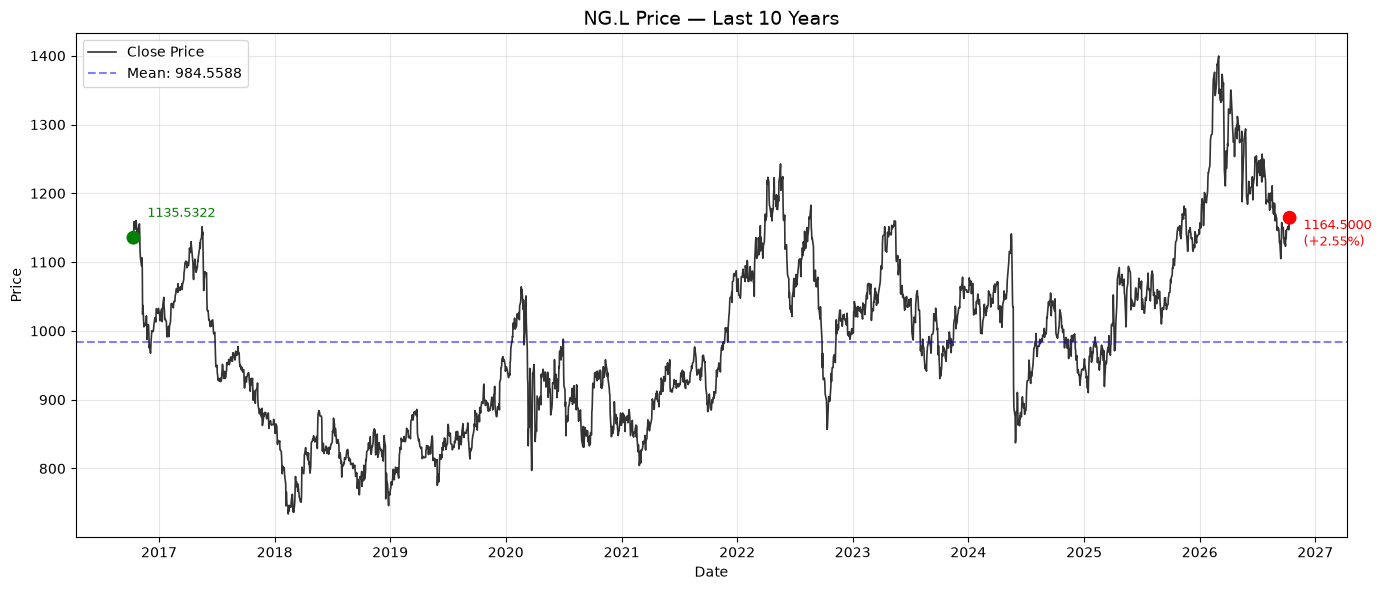

In [2]:
# === 1. Price Chart & Percentage Change (Last 10 Years) ===
cutoff_price = df.index.max() - pd.DateOffset(years=10)
df_price = df[df.index >= cutoff_price].copy()

start_price = df_price["Close"].iloc[0]
end_price = df_price["Close"].iloc[-1]
pct_change = (end_price - start_price) / start_price * 100

print("=== NG.L Price — Last 10 Years ===")
print(f"Start:  {df_price.index.min().date()}")
print(f"End:    {df_price.index.max().date()}")
print(f"Start Price:  {start_price:.4f}")
print(f"End Price:    {end_price:.4f}")
print(f"10Y Change:   {pct_change:+.2f}%")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df_price.index, df_price["Close"], color="#333", linewidth=1.2, label="Close Price")
ax.axhline(df_price["Close"].mean(), color="blue", linestyle="--", alpha=0.5, label=f"Mean: {df_price['Close'].mean():.4f}")
ax.scatter(df_price.index[[0, -1]], [start_price, end_price], color=["green", "red"], s=80, zorder=5)
ax.annotate(f"{start_price:.4f}", (df_price.index[0], start_price),
            textcoords="offset points", xytext=(10, 15), fontsize=9, color="green")
ax.annotate(f"{end_price:.4f}\n({pct_change:+.2f}%)", (df_price.index[-1], end_price),
            textcoords="offset points", xytext=(10, -20), fontsize=9, color="red", ha="left")
ax.set_title("NG.L Price — Last 10 Years", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Price")
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


=== EMA20 Signals (Last 10 Years) ===
Buy signals:  60
Sell signals: 59


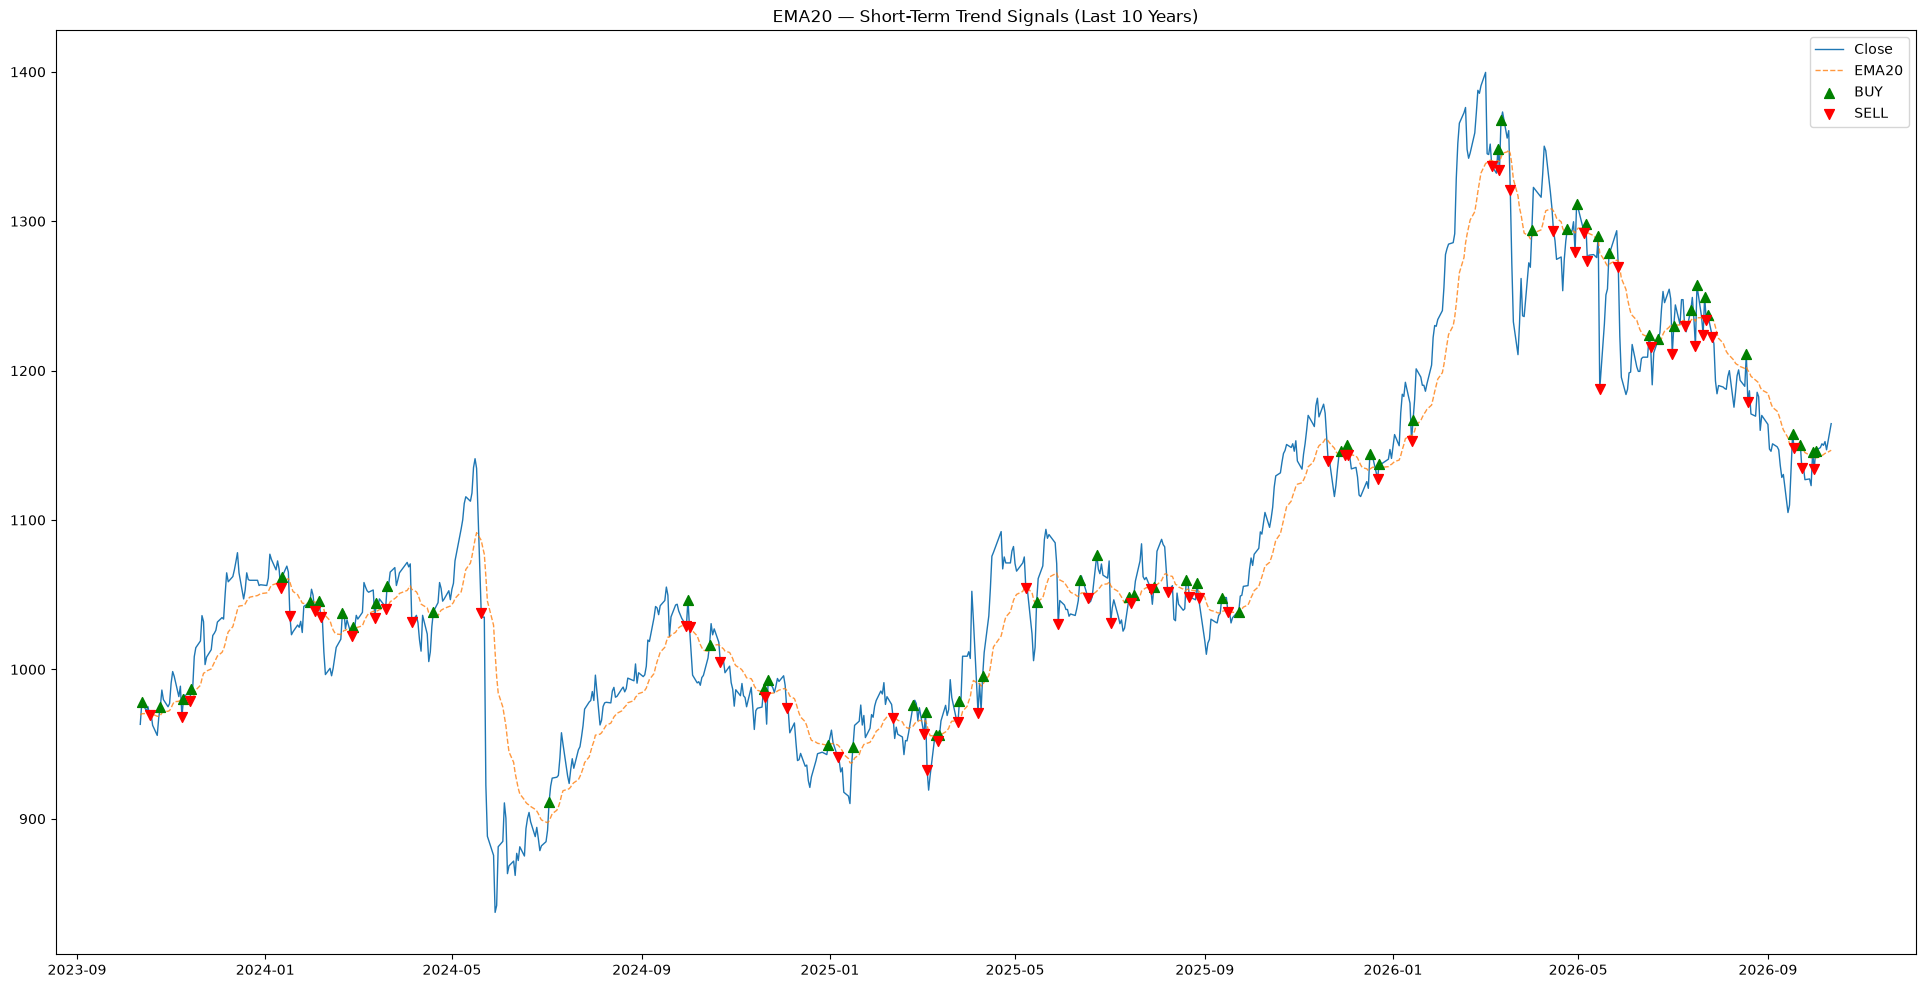

In [3]:
# === 2. EMA20 ===
ema20 = df["ta_ema20"]
close = df["Close"]

# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=3)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema20 = df_recent["ta_ema20"]

df_recent["price_above_ema20"] = close > ema20
df_recent["prev_above_ema20"] = df_recent["price_above_ema20"].shift(1)
df_recent["ema20_buy_signal"] = (df_recent["price_above_ema20"] == True) & (df_recent["prev_above_ema20"] == False)
df_recent["ema20_sell_signal"] = (df_recent["price_above_ema20"] == False) & (df_recent["prev_above_ema20"] == True)

print("=== EMA20 Signals (Last 10 Years) ===")
print(f"Buy signals:  {df_recent['ema20_buy_signal'].sum()}")
print(f"Sell signals: {df_recent['ema20_sell_signal'].sum()}")

ema20_buy_idx = df_recent[df_recent["ema20_buy_signal"]].index
ema20_buy_prices = close[ema20_buy_idx]
ema20_sell_idx = df_recent[df_recent["ema20_sell_signal"]].index
ema20_sell_prices = close[ema20_sell_idx]

fig, ax = plt.subplots(figsize=(24, 12))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema20, label="EMA20", linestyle="--", linewidth=1, alpha=0.8)
ax.scatter(ema20_buy_idx, ema20_buy_prices, marker="^", color="green", s=50, label="BUY", zorder=5)
ax.scatter(ema20_sell_idx, ema20_sell_prices, marker="v", color="red", s=50, label="SELL", zorder=5)
ax.legend()
ax.set_title("EMA20 — Short-Term Trend Signals (Last 10 Years)")
plt.show()


=== EMA50 Signals (Last 10 Years) ===
Time above EMA50: 52.2%
EMA20 > EMA50:    53.1%


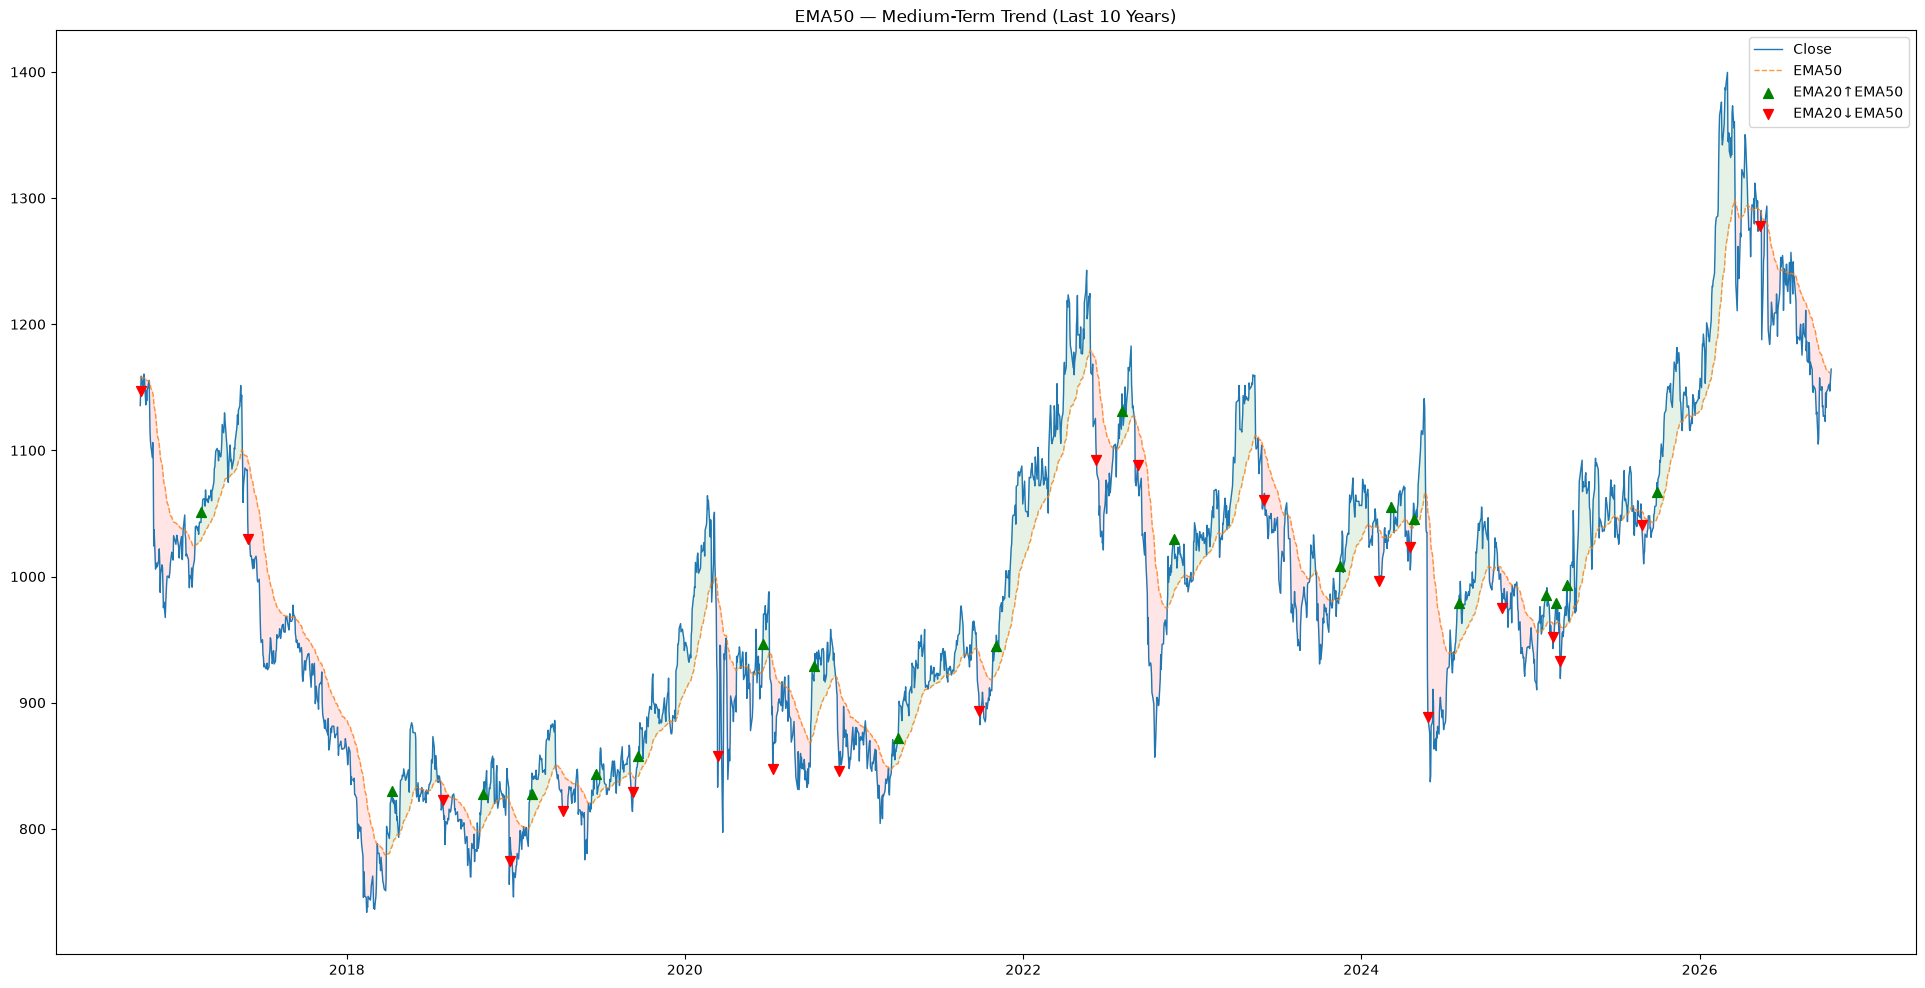

In [4]:
# === 3. EMA50 ===
ema50 = df["ta_ema50"]
close = df["Close"]

# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=10)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema20 = df_recent["ta_ema20"]
ema50 = df_recent["ta_ema50"]

df_recent["price_above_ema50"] = close > ema50
df_recent["ema20_above_ema50"] = ema20 > ema50
df_recent["prev_ema20_above_ema50"] = df_recent["ema20_above_ema50"].shift(1)
df_recent["ema50_buy_signal"] = df_recent["ema20_above_ema50"] == True
df_recent["ema50_sell_signal"] = df_recent["ema20_above_ema50"] == False
df_recent["golden_cross"] = (df_recent["ema20_above_ema50"] == True) & (df_recent["prev_ema20_above_ema50"] == False)
df_recent["death_cross"] = (df_recent["ema20_above_ema50"] == False) & (df_recent["prev_ema20_above_ema50"] == True)

print("\n=== EMA50 Signals (Last 10 Years) ===")
print(f"Time above EMA50: {(df_recent['price_above_ema50']).mean()*100:.1f}%")
print(f"EMA20 > EMA50:    {(df_recent['ema20_above_ema50']).mean()*100:.1f}%")

ema50_cross_buy_idx = df_recent[df_recent["golden_cross"]].index
ema50_cross_buy_prices = close[ema50_cross_buy_idx]
ema50_cross_sell_idx = df_recent[df_recent["death_cross"]].index
ema50_cross_sell_prices = close[ema50_cross_sell_idx]

fig, ax = plt.subplots(figsize=(24, 12))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema50, label="EMA50", linestyle="--", linewidth=1, alpha=0.8)
ax.fill_between(close.index, close, ema50, where=(close >= ema50), alpha=0.1, color="green")
ax.fill_between(close.index, close, ema50, where=(close < ema50), alpha=0.1, color="red")
ax.scatter(ema50_cross_buy_idx, ema50_cross_buy_prices, marker="^", color="green", s=50, label="EMA20↑EMA50", zorder=5)
ax.scatter(ema50_cross_sell_idx, ema50_cross_sell_prices, marker="v", color="red", s=50, label="EMA20↓EMA50", zorder=5)
ax.legend()
ax.set_title("EMA50 — Medium-Term Trend (Last 10 Years)")
plt.show()


=== EMA200 Long-Term Regime (Last 10 Years) ===
Bull period: 50.9%
Bear period: 49.1%


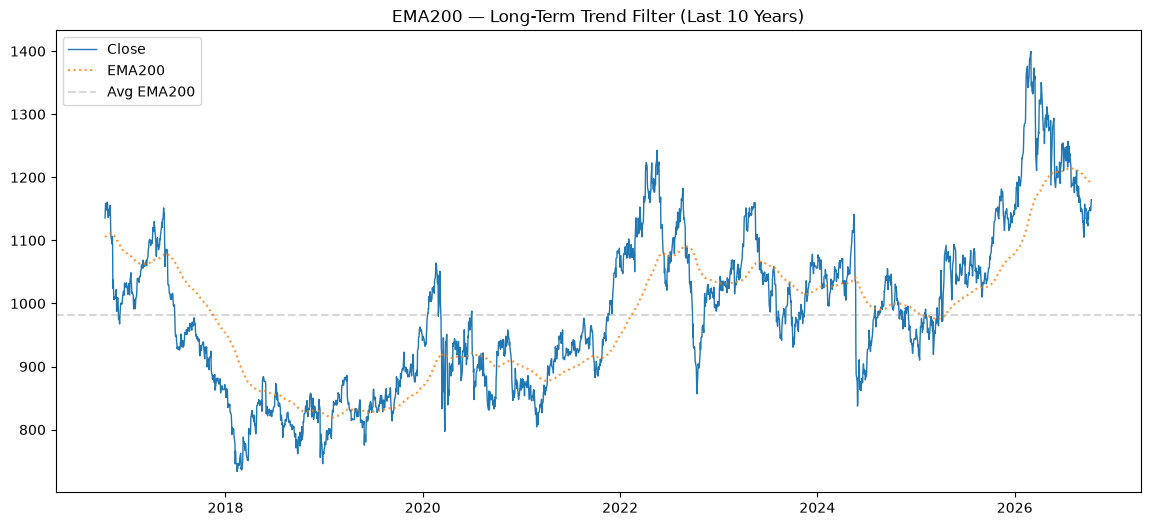

In [5]:
# === 4. EMA200 ===
ema200 = df["ta_ema200"]
close = df["Close"]

# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=10)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema200 = df_recent["ta_ema200"]

df_recent["price_above_ema200"] = close > ema200
df_recent["regime"] = df_recent["price_above_ema200"].map({True: "BULL", False: "BEAR"})

print("\n=== EMA200 Long-Term Regime (Last 10 Years) ===")
print(f"Bull period: {(df_recent['regime'] == 'BULL').mean()*100:.1f}%")
print(f"Bear period: {(df_recent['regime'] == 'BEAR').mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema200, label="EMA200", linestyle=":", linewidth=1.5, alpha=0.8)
ax.axhline(ema200.mean(), color="gray", linestyle="--", alpha=0.3, label="Avg EMA200")
ax.legend()
ax.set_title("EMA200 — Long-Term Trend Filter (Last 10 Years)")
plt.show()


=== Golden Cross / Death Cross (Last 10 Years) ===
Golden Crosses: 10
Death Crosses:  11


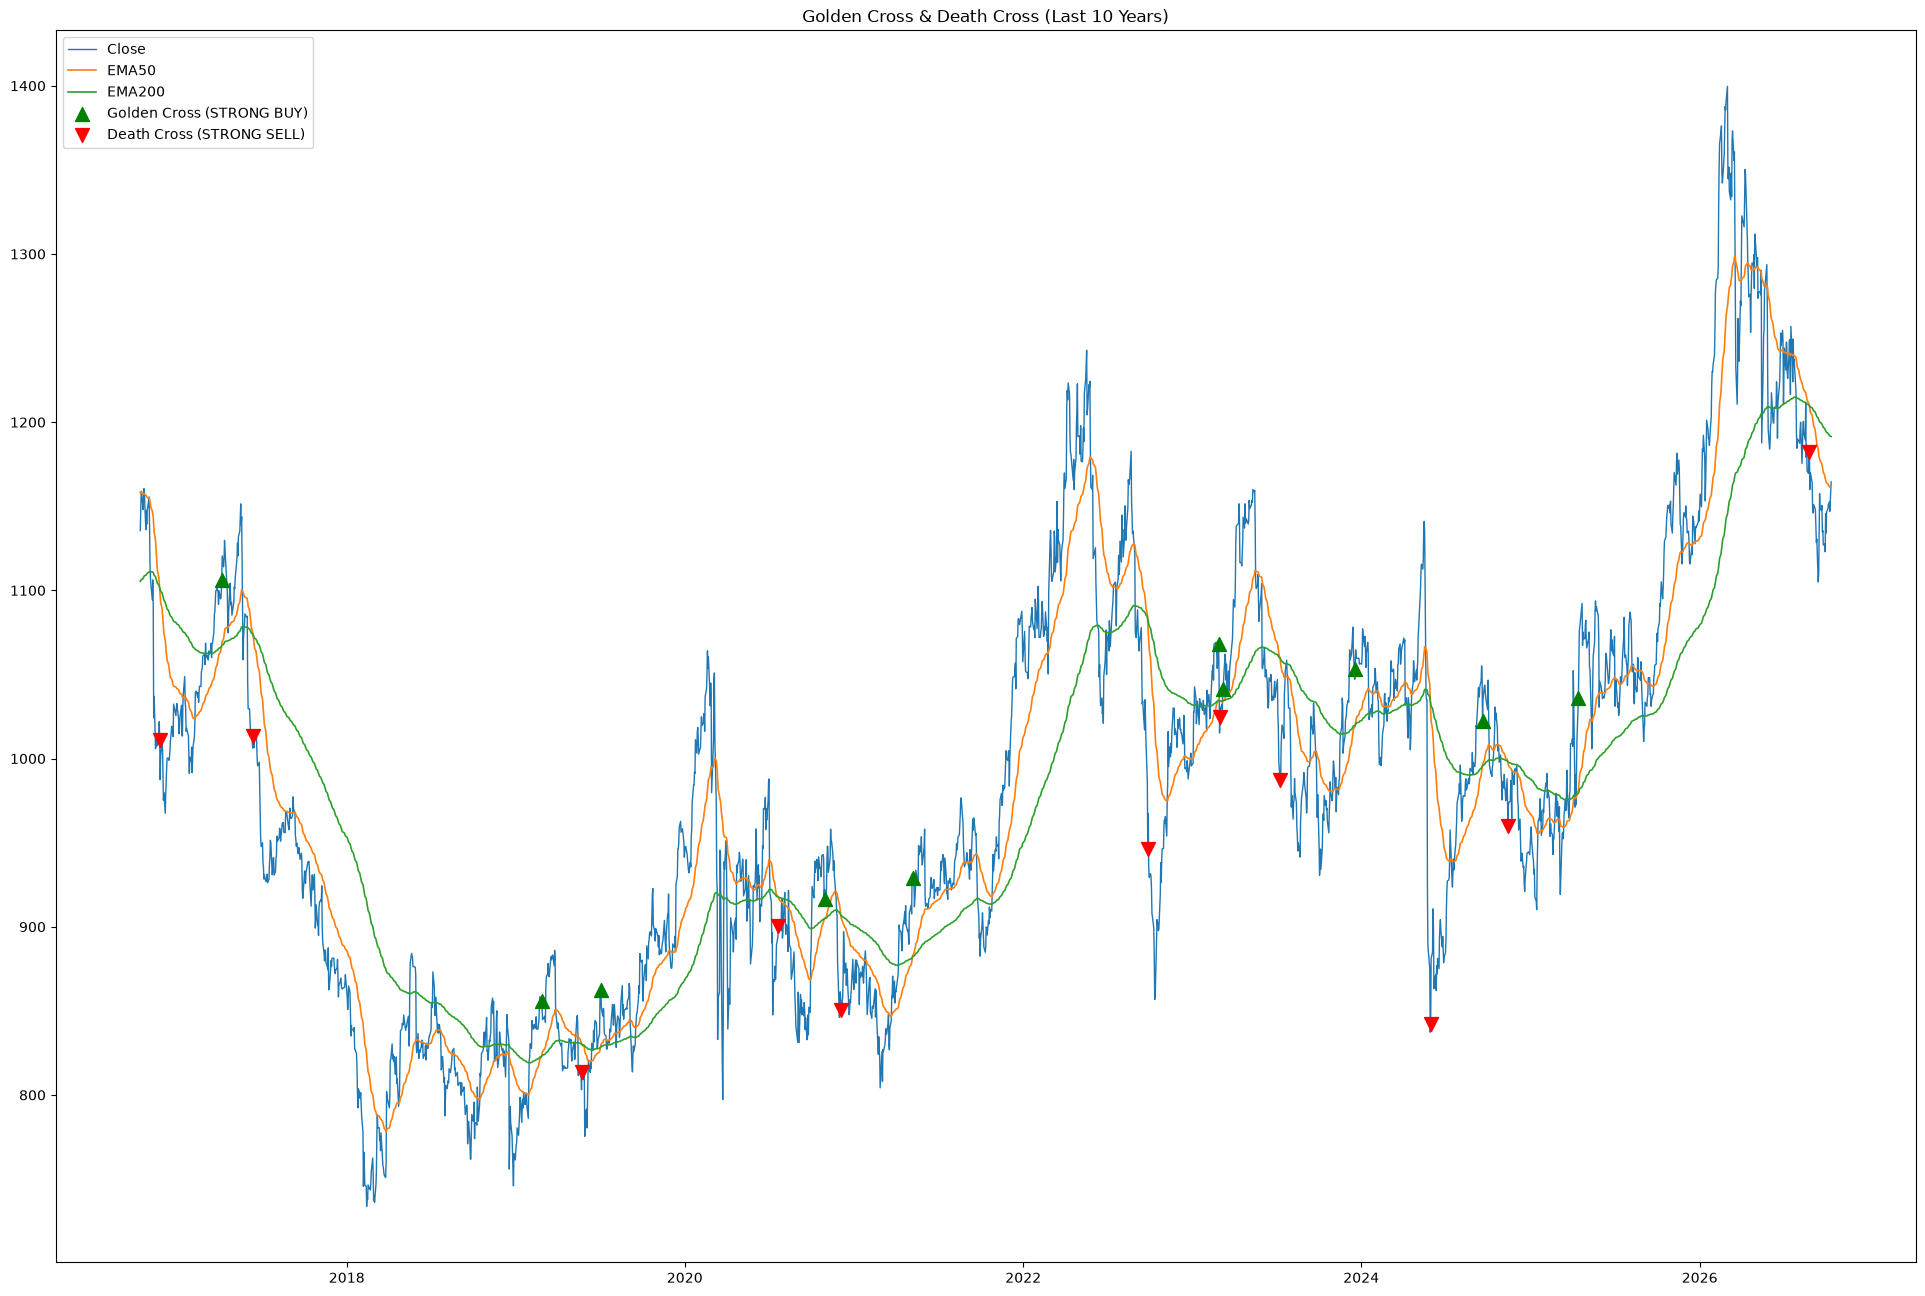

In [6]:
# === 5. Golden Cross & Death Cross ===
# --- COMPUTE ON FULL DF SO LATER SECTIONS CAN REFERENCE ---
close_all = df["Close"]
ema50_all = df["ta_ema50"]
ema200_all = df["ta_ema200"]

df["ema50_above_ema200"] = ema50_all > ema200_all
df["prev_ema50_above_ema200"] = df["ema50_above_ema200"].shift(1)
df["golden_cross_strong"] = (df["ema50_above_ema200"] == True) & (df["prev_ema50_above_ema200"] == False)
df["death_cross_strong"] = (df["ema50_above_ema200"] == False) & (df["prev_ema50_above_ema200"] == True)

# --- FILTER TO LAST 10 YEARS FOR DISPLAY ---
cutoff = df.index.max() - pd.DateOffset(years=10)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema50 = df_recent["ta_ema50"]
ema200 = df_recent["ta_ema200"]

print("\n=== Golden Cross / Death Cross (Last 10 Years) ===")
print(f"Golden Crosses: {df_recent['golden_cross_strong'].sum()}")
print(f"Death Crosses:  {df_recent['death_cross_strong'].sum()}")

gc_idx = df_recent[df_recent["golden_cross_strong"]].index
gc_prices = close[gc_idx]
dc_idx = df_recent[df_recent["death_cross_strong"]].index
dc_prices = close[dc_idx]

fig, ax = plt.subplots(figsize=(24, 16))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, ema50, label="EMA50", linewidth=1.2)
ax.plot(close.index, ema200, label="EMA200", linewidth=1.2)
ax.scatter(gc_idx, gc_prices, marker="^", color="green", s=100, zorder=5, label="Golden Cross (STRONG BUY)")
ax.scatter(dc_idx, dc_prices, marker="v", color="red", s=100, zorder=5, label="Death Cross (STRONG SELL)")
ax.legend()
ax.set_title("Golden Cross & Death Cross (Last 10 Years)")
plt.show()


=== SuperTrend Signals (Last 10 Years) ===
Buy signals:  92
Sell signals: 93


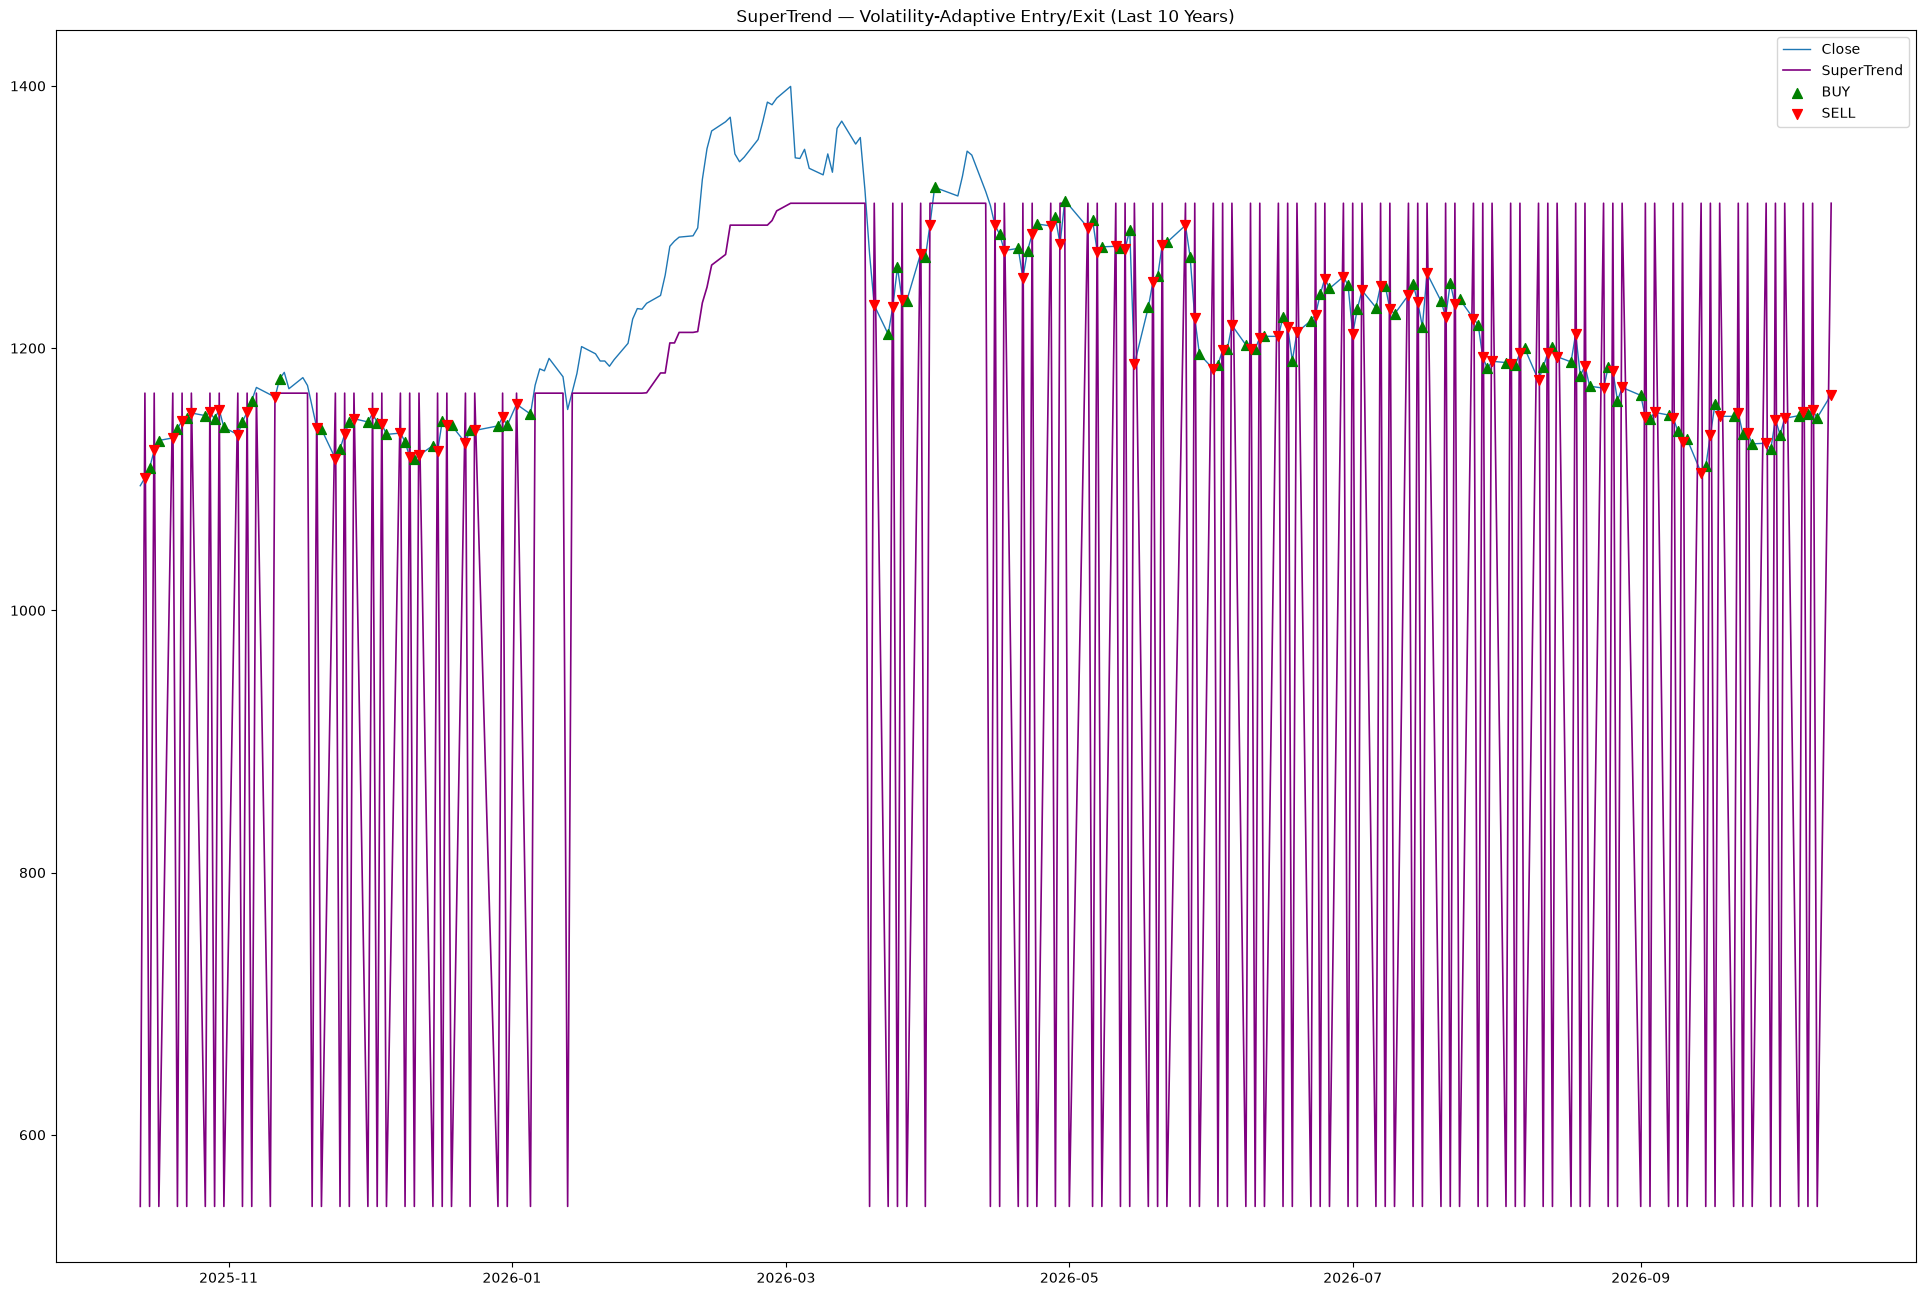

In [7]:
# === 6. SuperTrend ===
# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(months=12)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
st = df_recent["ta_supertrend"]
st_dir = df_recent["ta_supertrend_direction"]

df_recent["price_above_st"] = close > st
df_recent["prev_above_st"] = df_recent["price_above_st"].shift(1)
df_recent["st_buy"] = (df_recent["price_above_st"] == True) & (df_recent["prev_above_st"] == False)
df_recent["st_sell"] = (df_recent["price_above_st"] == False) & (df_recent["prev_above_st"] == True)

print("\n=== SuperTrend Signals (Last 10 Years) ===")
print(f"Buy signals:  {df_recent['st_buy'].sum()}")
print(f"Sell signals: {df_recent['st_sell'].sum()}")

st_buy_idx = df_recent[df_recent["st_buy"]].index
st_buy_prices = close[st_buy_idx]
st_sell_idx = df_recent[df_recent["st_sell"]].index
st_sell_prices = close[st_sell_idx]

fig, ax = plt.subplots(figsize=(24, 16))
ax.plot(close.index, close, label="Close", linewidth=1)
ax.plot(close.index, st, label="SuperTrend", linewidth=1.2, color="purple")
ax.scatter(st_buy_idx, st_buy_prices, marker="^", color="green", s=50, zorder=5, label="BUY")
ax.scatter(st_sell_idx, st_sell_prices, marker="v", color="red", s=50, zorder=5, label="SELL")
ax.legend()
ax.set_title("SuperTrend — Volatility-Adaptive Entry/Exit (Last 10 Years)")
plt.show()

In [8]:
# === 7. Combined Trend Score ===
# --- FILTER TO LAST 10 YEARS ---
cutoff = df.index.max() - pd.DateOffset(years=10)
df_recent = df[df.index >= cutoff]

close = df_recent["Close"]
ema20 = df_recent["ta_ema20"]
ema50 = df_recent["ta_ema50"]
ema200 = df_recent["ta_ema200"]
st_dir = df_recent["ta_supertrend_direction"].fillna(-1)

df_recent["score_ema20"] = (close > ema20).astype(int) * 2 - 1
df_recent["score_ema50"] = (close > ema50).astype(int) * 2 - 1
df_recent["score_ema200"] = (close > ema200).astype(int) * 2 - 1
df_recent["score_cross"] = (ema50 > ema200).astype(int) * 2 - 1
df_recent["score_st"] = st_dir

df_recent["trend_score"] = df_recent["score_ema20"] + df_recent["score_ema50"] + df_recent["score_ema200"] + df_recent["score_cross"] + df_recent["score_st"]

def classify(score):
    if score >= 4: return "STRONG BUY"
    elif score >= 2: return "BUY"
    elif score == 0: return "NEUTRAL"
    elif score >= -2: return "SELL"
    else: return "STRONG SELL"

df_recent["trend_classification"] = df_recent["trend_score"].apply(classify)

print("\n=== Combined Trend Classification (Last 10 Years) ===")
print(df_recent["trend_classification"].value_counts())

print("\n=== Latest Assessment ===")
latest = df_recent.iloc[-1]
print(f"Date: {latest.name.strftime('%Y-%m-%d')}  Close: {latest['Close']:.2f}")
print(f"EMA20:  {'Bullish' if latest['Close'] > latest['ta_ema20'] else 'Bearish'}")
print(f"EMA50:  {'Bullish' if latest['Close'] > latest['ta_ema50'] else 'Bearish'}")
print(f"EMA200: {'Bullish' if latest['Close'] > latest['ta_ema200'] else 'Bearish'}")
print(f"Cross:  {'Bullish' if latest['ta_ema50'] > latest['ta_ema200'] else 'Bearish'}")
print(f"ST:     {'Bullish' if latest['ta_supertrend_direction'] == 1 else 'Bearish'}")
print(f"Score:  {latest['trend_classification']} ({int(latest['trend_score'])}/5)")


=== Combined Trend Classification (Last 10 Years) ===
trend_classification
SELL           821
STRONG SELL    788
BUY            502
STRONG BUY     415
Name: count, dtype: int64

=== Latest Assessment ===
Date: 2026-10-12  Close: 1164.50
EMA20:  Bullish
EMA50:  Bullish
EMA200: Bearish
Cross:  Bearish
ST:     Bullish
Score:  SELL (1/5)


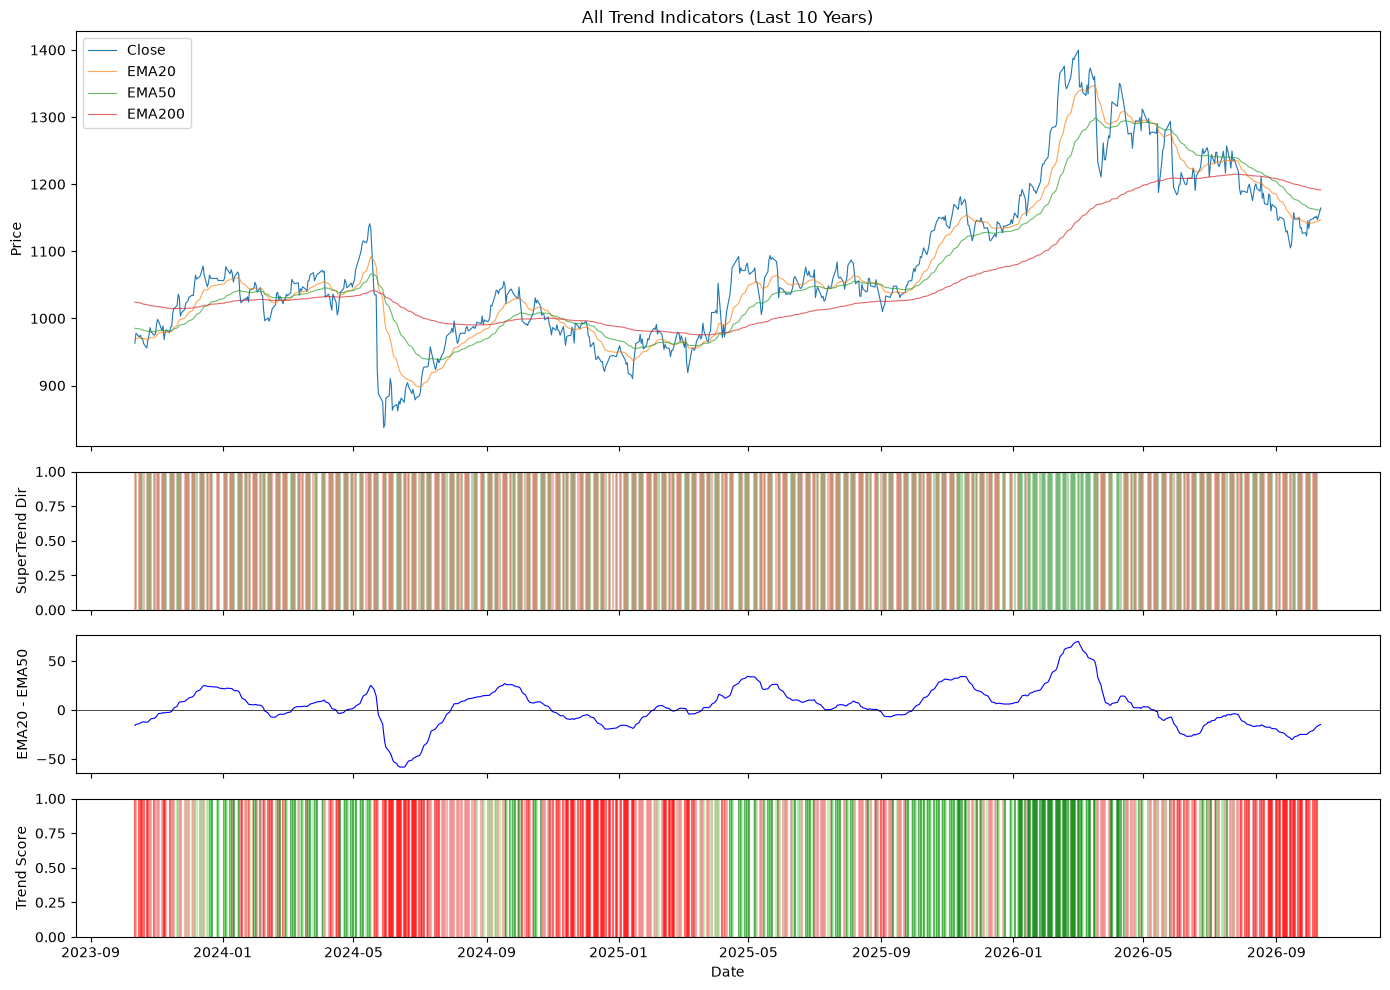

In [9]:
# === 8. Combined Timeline ===
# --- FILTER TO LAST 10 YEARS (self-contained) ---
cutoff8 = df.index.max() - pd.DateOffset(years=3)
df8 = df[df.index >= cutoff8]
close8 = df8["Close"]
ema20_8 = df8["ta_ema20"]
ema50_8 = df8["ta_ema50"]
ema200_8 = df8["ta_ema200"]
st_dir_8 = df8["ta_supertrend_direction"].fillna(-1)

df8["score_ema20"] = (close8 > ema20_8).astype(int) * 2 - 1
df8["score_ema50"] = (close8 > ema50_8).astype(int) * 2 - 1
df8["score_ema200"] = (close8 > ema200_8).astype(int) * 2 - 1
df8["score_cross"] = (ema50_8 > ema200_8).astype(int) * 2 - 1
df8["score_st"] = st_dir_8
df8["trend_score"] = df8["score_ema20"] + df8["score_ema50"] + df8["score_ema200"] + df8["score_cross"] + df8["score_st"]
df8["trend_classification"] = df8["trend_score"].apply(classify)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1, 1]})

axes[0].plot(close8.index, close8, label="Close", linewidth=0.8)
axes[0].plot(close8.index, ema20_8, label="EMA20", linewidth=0.8, alpha=0.7)
axes[0].plot(close8.index, ema50_8, label="EMA50", linewidth=0.8, alpha=0.7)
axes[0].plot(close8.index, ema200_8, label="EMA200", linewidth=0.8, alpha=0.7)
axes[0].set_ylabel("Price")
axes[0].legend(loc="upper left")
axes[0].set_title("All Trend Indicators (Last 10 Years)")

st_colors = st_dir_8.map({1: "green", -1: "red"})
for i in range(len(df8) - 1):
    axes[1].axvline(df8.index[i], color=st_colors.iloc[i], alpha=0.3)
axes[1].set_ylabel("SuperTrend Dir")

df8["ema_diff"] = ema20_8 - ema50_8
axes[2].plot(df8.index, df8["ema_diff"], color="blue", linewidth=0.8)
axes[2].axhline(0, color="black", linestyle="-", linewidth=0.5)
axes[2].set_ylabel("EMA20 - EMA50")

colors_map = {"STRONG BUY": "green", "BUY": "lightgreen", "NEUTRAL": "gray", "SELL": "lightcoral", "STRONG SELL": "red"}
class_colors = df8["trend_classification"].map(colors_map)
for i in range(len(df8) - 1):
    axes[3].axvline(df8.index[i], color=class_colors.iloc[i], alpha=0.6)
axes[3].set_ylabel("Trend Score")
axes[3].set_xlabel("Date")

plt.tight_layout()
plt.show()

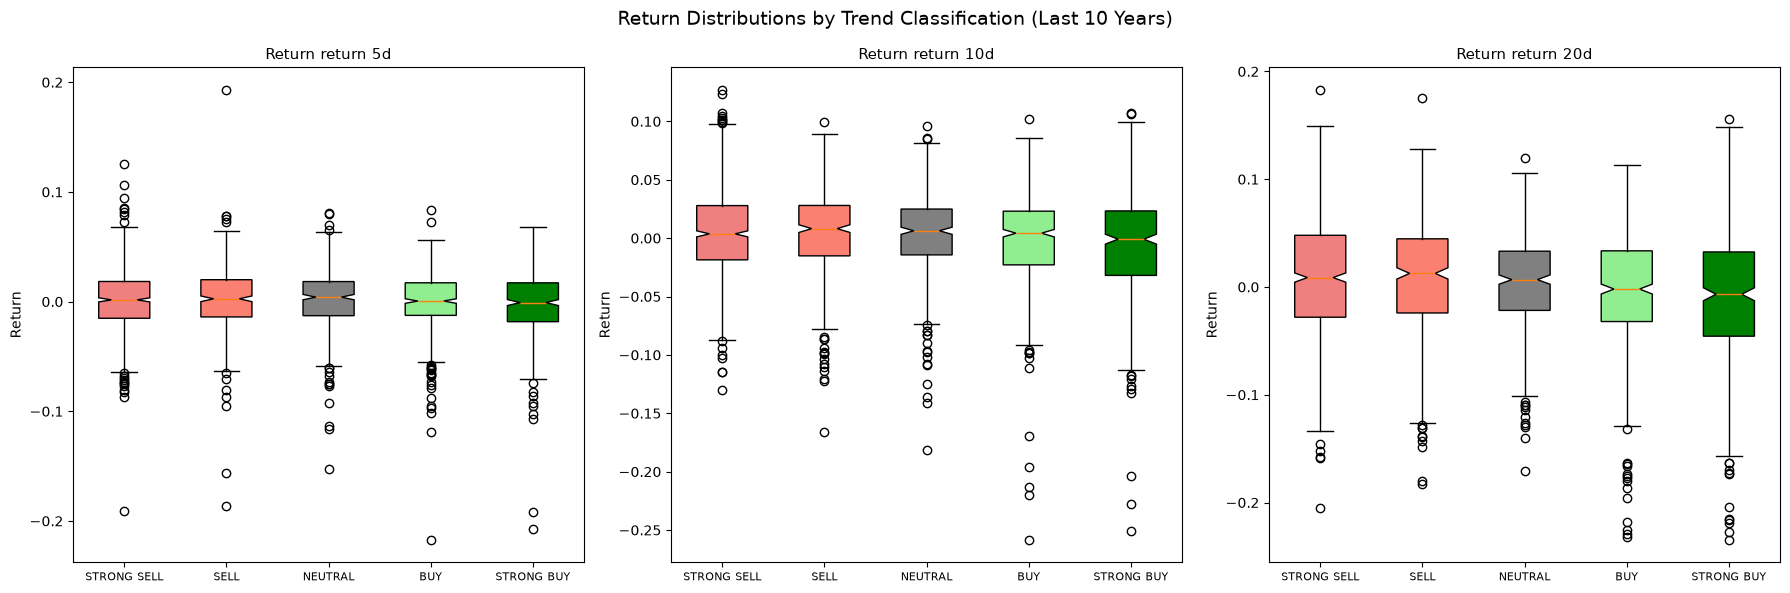

Return Summary by Trend Classification
                      count  avg_return_5d  avg_return_10d  avg_return_20d  median_return_5d  std_return_5d
trend_classification                                                                                       
STRONG SELL             786        0.00199         0.00394         0.00930           0.00159        0.02837
SELL                    421        0.00240         0.00414         0.00633           0.00256        0.03011
NEUTRAL                 397        0.00081         0.00198         0.00287           0.00409        0.02809
BUY                     502       -0.00081        -0.00185        -0.00520           0.00052        0.02790
STRONG BUY              415       -0.00330        -0.00643        -0.01044          -0.00088        0.03205


In [10]:
# === 9. Return Distributions by Trend Classification ===
cutoff9 = df.index.max() - pd.DateOffset(years=10)
df9 = df[df.index >= cutoff9].copy()

def classify(score):
    if score >= 4: return "STRONG BUY"
    if score >= 2: return "BUY"
    if score >= 0: return "NEUTRAL"
    if score >= -2: return "SELL"
    return "STRONG SELL"

st_dir9 = df9["ta_supertrend_direction"].fillna(-1)
df9["score_ema20"] = (df9["Close"] > df9["ta_ema20"]).astype(int) * 2 - 1
df9["score_ema50"] = (df9["Close"] > df9["ta_ema50"]).astype(int) * 2 - 1
df9["score_ema200"] = (df9["Close"] > df9["ta_ema200"]).astype(int) * 2 - 1
df9["score_cross"] = (df9["ta_ema50"] > df9["ta_ema200"]).astype(int) * 2 - 1
df9["score_st"] = st_dir9
df9["trend_score"] = df9["score_ema20"] + df9["score_ema50"] + df9["score_ema200"] + df9["score_cross"] + df9["score_st"]
df9["trend_classification"] = df9["trend_score"].apply(classify)

order = ["STRONG SELL", "SELL", "NEUTRAL", "BUY", "STRONG BUY"]
colors_map = {"STRONG SELL": "lightcoral", "SELL": "salmon", "NEUTRAL": "gray", "BUY": "lightgreen", "BUY": "lightgreen", "STRONG BUY": "green"}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, ret_col in zip(axes, ["ta_return_5d", "ta_return_10d", "ta_return_20d"]):
    plot_data = []
    for cat in order:
        vals = df9.loc[df9["trend_classification"] == cat, ret_col].dropna().values
        plot_data.append(vals)
    bp = ax.boxplot(plot_data, notch=True, patch_artist=True)
    ax.set_xticklabels(order, fontsize=8)
    for patch, cat in zip(bp["boxes"], order):
        patch.set_facecolor(colors_map[cat])
    ax.set_title(ret_col.replace("ta_", "Return ").replace("_", " "), fontsize=11)
    ax.set_ylabel("Return")
plt.suptitle("Return Distributions by Trend Classification (Last 10 Years)", fontsize=14)
plt.tight_layout()
plt.show()

summary = df9.groupby("trend_classification").agg(
    count=("ta_return_5d", "count"),
    avg_return_5d=("ta_return_5d", "mean"),
    avg_return_10d=("ta_return_10d", "mean"),
    avg_return_20d=("ta_return_20d", "mean"),
    median_return_5d=("ta_return_5d", "median"),
    std_return_5d=("ta_return_5d", "std"),
).round(5)
# Reorder rows
summary = summary.reindex(order)
print("Return Summary by Trend Classification")
print(summary.to_string())

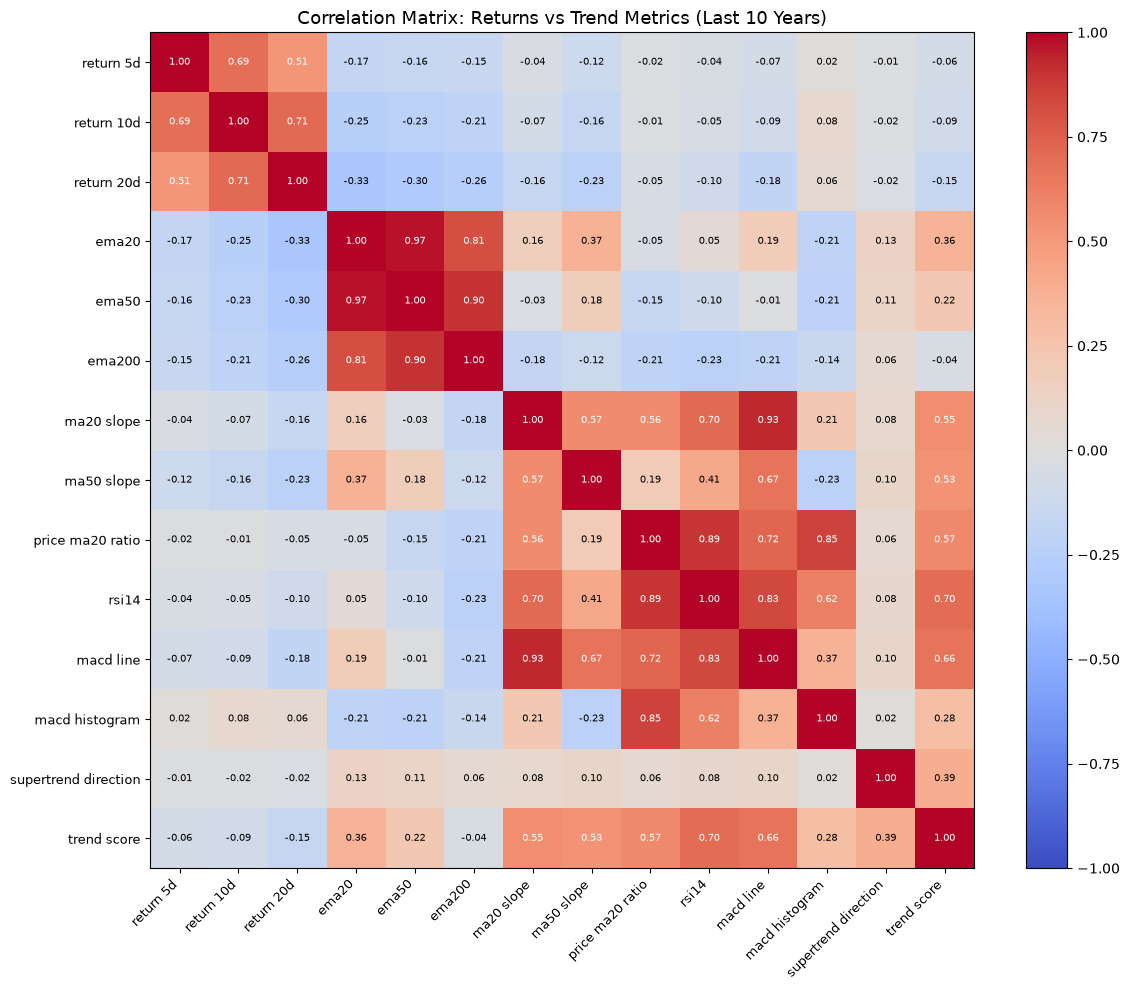

In [11]:
# === 10. Correlation: Returns vs Trend Metrics ===
cutoff10 = df.index.max() - pd.DateOffset(years=5)
df10 = df[df.index >= cutoff10].copy()

st_dir10 = df10["ta_supertrend_direction"].fillna(-1)
df10["score_ema20"] = (df10["Close"] > df10["ta_ema20"]).astype(int) * 2 - 1
df10["score_ema50"] = (df10["Close"] > df10["ta_ema50"]).astype(int) * 2 - 1
df10["score_ema200"] = (df10["Close"] > df10["ta_ema200"]).astype(int) * 2 - 1
df10["score_cross"] = (df10["ta_ema50"] > df10["ta_ema200"]).astype(int) * 2 - 1
df10["score_st"] = st_dir10
df10["trend_score"] = (df10["score_ema20"] + df10["score_ema50"] + df10["score_ema200"] + df10["score_cross"] + df10["score_st"])

corr_cols = [
    "ta_return_5d", "ta_return_10d", "ta_return_20d",
    "ta_ema20", "ta_ema50", "ta_ema200",
    "ta_ma20_slope", "ta_ma50_slope",
    "ta_price_ma20_ratio",
    "ta_rsi14", "ta_macd_line", "ta_macd_histogram",
    "ta_supertrend_direction", "trend_score"
]
corr_data = df10[corr_cols].dropna()

corr_matrix = corr_data.corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr_matrix.values, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels([c.replace("ta_", "").replace("_", " ") for c in corr_matrix.columns], rotation=45, ha="right", fontsize=9)
ax.set_yticklabels([c.replace("ta_", "").replace("_", " ") for c in corr_matrix.columns], fontsize=9)

for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        val = corr_matrix.values[i, j]
        color = "white" if abs(val) > 0.5 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7, color=color)

fig.colorbar(im, ax=ax)
ax.set_title("Correlation Matrix: Returns vs Trend Metrics (Last 10 Years)", fontsize=13)
plt.tight_layout()
plt.show()

     Signal  Count  Avg Return 5d  Avg Return 10d  Avg Return 20d  Median Return 5d  Win Rate 5d  Win Rate 10d  Win Rate 20d
 STRONG BUY    275      -0.001900       -0.002795       -0.005871          0.000357     0.501818      0.541818      0.454545
        BUY    262       0.001900        0.002336       -0.000287          0.004398     0.545802      0.587786      0.503817
    NEUTRAL    211       0.002572        0.004085        0.008329          0.004619     0.563981      0.597156      0.578199
       SELL    230       0.000144        0.001327        0.005673          0.002184     0.552174      0.586957      0.569565
STRONG SELL    284       0.004577        0.008999        0.019237          0.008104     0.598592      0.633803      0.616197


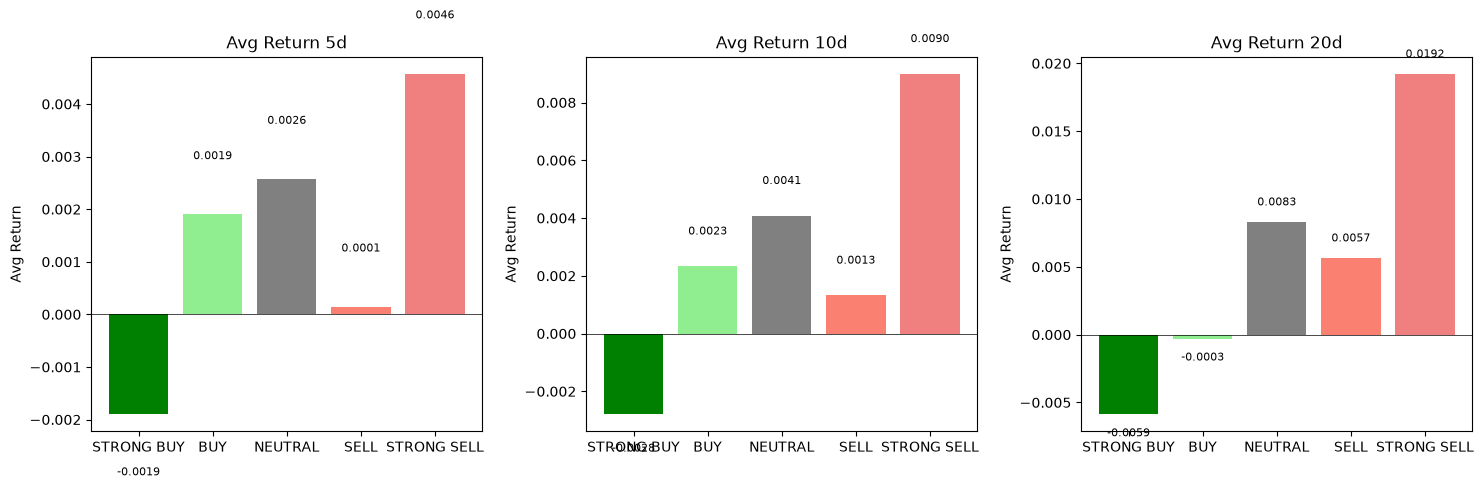

In [12]:
# === 11. Trend Signal -> Forward Return Analysis ===
cutoff11 = df.index.max() - pd.DateOffset(years=5)
df11 = df[df.index >= cutoff11].copy()

st_dir11 = df11["ta_supertrend_direction"].fillna(-1)
df11["score_ema20"] = (df11["Close"] > df11["ta_ema20"]).astype(int) * 2 - 1
df11["score_ema50"] = (df11["Close"] > df11["ta_ema50"]).astype(int) * 2 - 1
df11["score_ema200"] = (df11["Close"] > df11["ta_ema200"]).astype(int) * 2 - 1
df11["score_cross"] = (df11["ta_ema50"] > df11["ta_ema200"]).astype(int) * 2 - 1
df11["score_st"] = st_dir11
df11["trend_score"] = (df11["score_ema20"] + df11["score_ema50"] + df11["score_ema200"] + df11["score_cross"] + df11["score_st"])
df11["trend_classification"] = df11["trend_score"].apply(classify)

buckets = ["STRONG BUY", "BUY", "NEUTRAL", "SELL", "STRONG SELL"]
results = []
for bucket in buckets:
    subset = df11[df11["trend_classification"] == bucket]
    results.append({
        "Signal": bucket,
        "Count": len(subset),
        "Avg Return 5d": subset["ta_return_5d"].mean(),
        "Avg Return 10d": subset["ta_return_10d"].mean(),
        "Avg Return 20d": subset["ta_return_20d"].mean(),
        "Median Return 5d": subset["ta_return_5d"].median(),
        "Win Rate 5d": (subset["ta_return_5d"] > 0).mean(),
        "Win Rate 10d": (subset["ta_return_10d"] > 0).mean(),
        "Win Rate 20d": (subset["ta_return_20d"] > 0).mean(),
    })

summary_df = pd.DataFrame(results)
print(summary_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, ret_key in zip(axes, ["Avg Return 5d", "Avg Return 10d", "Avg Return 20d"]):
    values = summary_df[ret_key]
    bar_colors = [colors_map[b] for b in buckets]
    bars = ax.bar(buckets, values, color=bar_colors)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_ylabel("Avg Return")
    ax.set_title(ret_key)
    for bar, val in zip(bars, values):
        offset = 0.001 if bar.get_height() >= 0 else -0.001
        va = "bottom" if bar.get_height() >= 0 else "top"
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset,
                f"{val:.4f}", ha="center", va=va, fontsize=8)
plt.tight_layout()
plt.show()

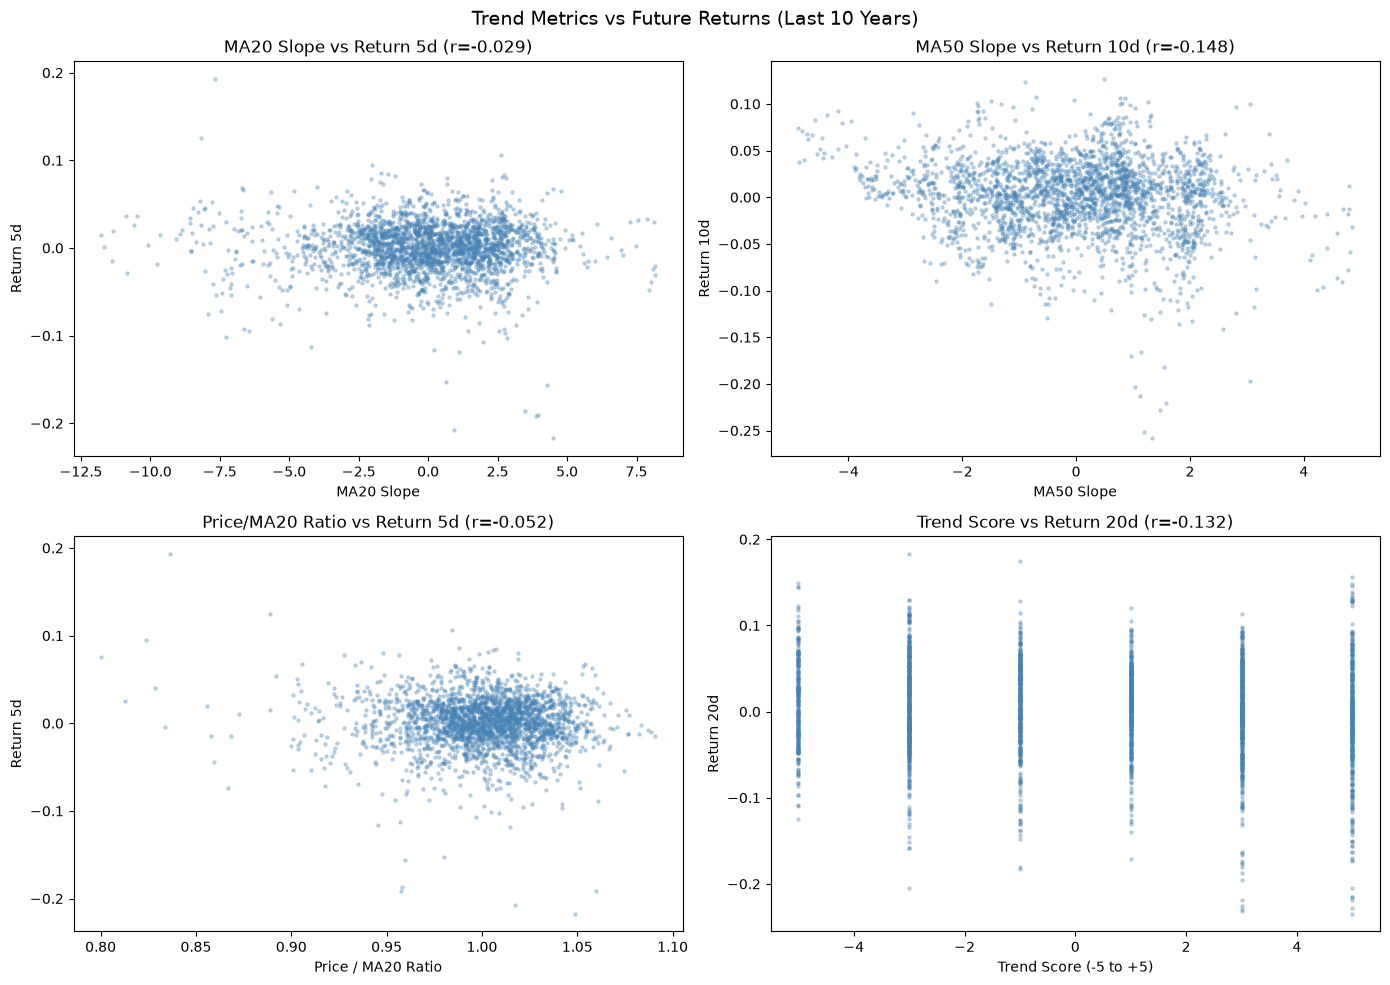

In [13]:
# === 12. EMA Slope & Price Ratio vs Returns ===
cutoff12 = df.index.max() - pd.DateOffset(years=10)
df12 = df[df.index >= cutoff12].copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 12a. MA20 Slope vs Return 5d
axes[0, 0].scatter(df12["ta_ma20_slope"], df12["ta_return_5d"], alpha=0.3, s=5, color="steelblue")
axes[0, 0].set_xlabel("MA20 Slope")
axes[0, 0].set_ylabel("Return 5d")
r1 = df12['ta_ma20_slope'].corr(df12['ta_return_5d'])
axes[0, 0].set_title(f"MA20 Slope vs Return 5d (r={r1:.3f})")

# 12b. MA50 Slope vs Return 10d
axes[0, 1].scatter(df12["ta_ma50_slope"], df12["ta_return_10d"], alpha=0.3, s=5, color="steelblue")
axes[0, 1].set_xlabel("MA50 Slope")
axes[0, 1].set_ylabel("Return 10d")
r2 = df12['ta_ma50_slope'].corr(df12['ta_return_10d'])
axes[0, 1].set_title(f"MA50 Slope vs Return 10d (r={r2:.3f})")

# 12c. Price/MA20 Ratio vs Return 5d
axes[1, 0].scatter(df12["ta_price_ma20_ratio"], df12["ta_return_5d"], alpha=0.3, s=5, color="steelblue")
axes[1, 0].set_xlabel("Price / MA20 Ratio")
axes[1, 0].set_ylabel("Return 5d")
r3 = df12['ta_price_ma20_ratio'].corr(df12['ta_return_5d'])
axes[1, 0].set_title(f"Price/MA20 Ratio vs Return 5d (r={r3:.3f})")

# 12d. Trend Score vs Return 20d
st_dir12 = df12["ta_supertrend_direction"].fillna(-1)
df12["score_ema20"] = (df12["Close"] > df12["ta_ema20"]).astype(int) * 2 - 1
df12["score_ema50"] = (df12["Close"] > df12["ta_ema50"]).astype(int) * 2 - 1
df12["score_ema200"] = (df12["Close"] > df12["ta_ema200"]).astype(int) * 2 - 1
df12["score_cross"] = (df12["ta_ema50"] > df12["ta_ema200"]).astype(int) * 2 - 1
df12["score_st"] = st_dir12
df12["trend_score"] = (df12["score_ema20"] + df12["score_ema50"] + df12["score_ema200"] + df12["score_cross"] + df12["score_st"])
axes[1, 1].scatter(df12["trend_score"], df12["ta_return_20d"], alpha=0.3, s=5, color="steelblue")
axes[1, 1].set_xlabel("Trend Score (-5 to +5)")
axes[1, 1].set_ylabel("Return 20d")
r4 = df12['trend_score'].corr(df12['ta_return_20d'])
axes[1, 1].set_title(f"Trend Score vs Return 20d (r={r4:.3f})")

plt.suptitle("Trend Metrics vs Future Returns (Last 10 Years)", fontsize=14)
plt.tight_layout()
plt.show()

=== SuperTrend Regime: Bullish vs Bearish ===
Bullish days: 1320, Bearish days: 1206

return 5d:
  Bullish -> Avg: 0.00031, Median: 0.00157, Win Rate: 52.6%
  Bearish -> Avg: 0.00059, Median: 0.00186, Win Rate: 52.2%

return 10d:
  Bullish -> Avg: 0.00040, Median: 0.00430, Win Rate: 55.8%
  Bearish -> Avg: 0.00124, Median: 0.00456, Win Rate: 55.8%

return 20d:
  Bullish -> Avg: 0.00070, Median: 0.00240, Win Rate: 51.4%
  Bearish -> Avg: 0.00262, Median: 0.00499, Win Rate: 53.3%



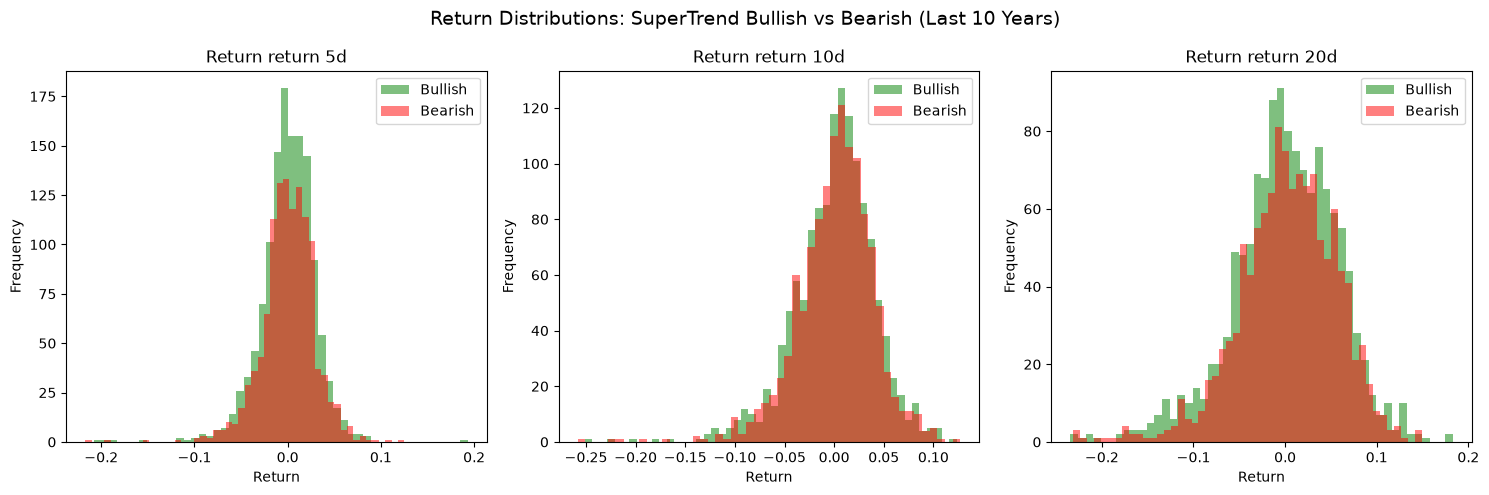

In [14]:
# === 13. SuperTrend Regime vs Returns ===
cutoff13 = df.index.max() - pd.DateOffset(years=10)
df13 = df[df.index >= cutoff13].copy()
df13["st_direction"] = df13["ta_supertrend_direction"].fillna(-1)

bull = df13[df13["st_direction"] == 1]
bear = df13[df13["st_direction"] == -1]

print("=== SuperTrend Regime: Bullish vs Bearish ===")
print(f"Bullish days: {len(bull)}, Bearish days: {len(bear)}")
print()
for ret_col in ["ta_return_5d", "ta_return_10d", "ta_return_20d"]:
    bull_avg = bull[ret_col].mean()
    bear_avg = bear[ret_col].mean()
    bull_med = bull[ret_col].median()
    bear_med = bear[ret_col].median()
    bull_win = (bull[ret_col] > 0).mean() * 100
    bear_win = (bear[ret_col] > 0).mean() * 100
    print(f"{ret_col.replace('ta_', '').replace('_', ' ')}:")
    print(f"  Bullish -> Avg: {bull_avg:.5f}, Median: {bull_med:.5f}, Win Rate: {bull_win:.1f}%")
    print(f"  Bearish -> Avg: {bear_avg:.5f}, Median: {bear_med:.5f}, Win Rate: {bear_win:.1f}%")
    print()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, ret_col in zip(axes, ["ta_return_5d", "ta_return_10d", "ta_return_20d"]):
    ax.hist(bull[ret_col].dropna(), bins=50, alpha=0.5, label="Bullish", color="green")
    ax.hist(bear[ret_col].dropna(), bins=50, alpha=0.5, label="Bearish", color="red")
    ax.set_xlabel("Return")
    ax.set_ylabel("Frequency")
    ax.set_title(ret_col.replace("ta_", "Return ").replace("_", " "))
    ax.legend()
plt.suptitle("Return Distributions: SuperTrend Bullish vs Bearish (Last 10 Years)", fontsize=14)
plt.tight_layout()
plt.show()

Golden Crosses (last 10y): 10
Death Crosses  (last 10y): 11

=== GOLDEN CROSS - Forward Returns ===
  ta_return_5d: mean=0.00274, median=0.00931
    win_rate=70.0%, min=-0.03364, max=0.03039
  ta_return_10d: mean=0.00995, median=0.01334
    win_rate=60.0%, min=-0.03815, max=0.04486
  ta_return_20d: mean=0.00459, median=-0.00045
    win_rate=50.0%, min=-0.04902, max=0.09248

=== DEATH CROSS - Forward Returns ===
  ta_return_5d: mean=0.00347, median=0.01417
    win_rate=54.5%, min=-0.03087, max=0.02903
  ta_return_10d: mean=0.00356, median=0.01712
    win_rate=63.6%, min=-0.06792, max=0.07201
  ta_return_20d: mean=-0.00360, median=-0.00865
    win_rate=45.5%, min=-0.08536, max=0.05699


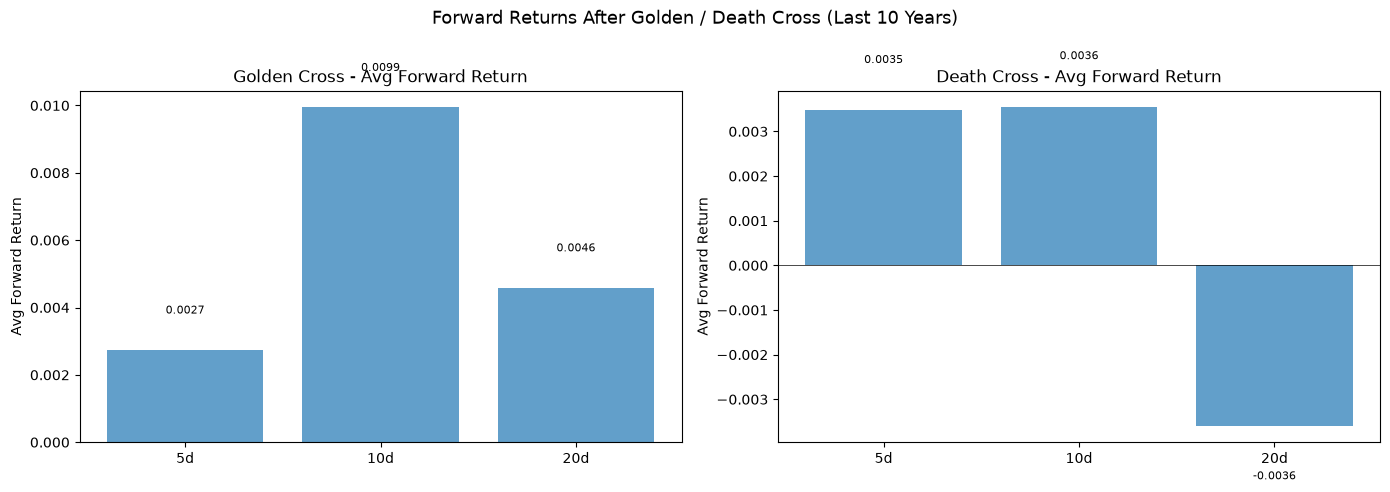


=== GOLDEN CROSS SIGNAL DETAILS ===
            ta_return_5d  ta_return_10d  ta_return_20d        Close
Date                                                               
2017-04-06      0.016185      -0.001962       0.012261  1106.400635
2019-02-26     -0.010247       0.026316       0.035398   855.681274
2019-07-04     -0.028324      -0.038150      -0.010405   862.162354
2020-10-30      0.017410       0.037650      -0.049020   916.408569
2021-05-07      0.004723       0.014704      -0.016548   929.232483
2023-02-27     -0.033645      -0.005608      -0.001869  1068.115112
2023-03-09      0.013895       0.011979       0.092477  1041.661743
2023-12-19      0.002845       0.019441      -0.026553  1053.153076
2024-09-19      0.014174      -0.009775       0.000978  1022.136841
2025-04-14      0.030391       0.044863       0.009166  1035.792480

=== DEATH CROSS SIGNAL DETAILS ===
            ta_return_5d  ta_return_10d  ta_return_20d        Close
Date                                       

In [15]:
# === 14. Forward Returns After Golden / Death Cross ===
# Event study: what happens in the 5d / 10d / 20d after each cross?
cutoff = df.index.max() - pd.DateOffset(years=10)
dfc = df[df.index >= cutoff].copy()

gc_days = dfc[dfc["golden_cross_strong"]].index
dc_days = dfc[dfc["death_cross_strong"]].index

print("Golden Crosses (last 10y):", len(gc_days))
print("Death Crosses  (last 10y):", len(dc_days))
print()

gc_ret = dfc.loc[gc_days, ["ta_return_5d", "ta_return_10d", "ta_return_20d", "Close"]].copy()
dc_ret = dfc.loc[dc_days, ["ta_return_5d", "ta_return_10d", "ta_return_20d", "Close"]].copy()

print("=== GOLDEN CROSS - Forward Returns ===")
for col in ["ta_return_5d", "ta_return_10d", "ta_return_20d"]:
    vals = gc_ret[col].dropna()
    print("  " + col + ": mean=" + f"{vals.mean():.5f}" + ", median=" + f"{vals.median():.5f}")
    print("    win_rate=" + f"{(vals > 0).mean():.1%}" + ", min=" + f"{vals.min():.5f}" + ", max=" + f"{vals.max():.5f}")

print()
print("=== DEATH CROSS - Forward Returns ===")
for col in ["ta_return_5d", "ta_return_10d", "ta_return_20d"]:
    vals = dc_ret[col].dropna()
    print("  " + col + ": mean=" + f"{vals.mean():.5f}" + ", median=" + f"{vals.median():.5f}")
    print("    win_rate=" + f"{(vals > 0).mean():.1%}" + ", min=" + f"{vals.min():.5f}" + ", max=" + f"{vals.max():.5f}")

# --- Visualize ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (sig_name, sig_df) in zip(axes, [("Golden Cross", gc_ret), ("Death Cross", dc_ret)]):
    bar_positions = []
    bar_values = []
    for i, col in enumerate(["ta_return_5d", "ta_return_10d", "ta_return_20d"]):
        bar_positions.append(["5d", "10d", "20d"][i])
        bar_values.append(sig_df[col].dropna().mean())
    ax.bar(bar_positions, bar_values, alpha=0.7)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_ylabel("Avg Forward Return")
    ax.set_title(sig_name + " - Avg Forward Return")
    for bp, bv in zip(bar_positions, bar_values):
        offset = 0.001 if bv >= 0 else -0.001
        va = "bottom" if bv >= 0 else "top"
        ax.text(bp, bv + offset, f"{bv:.4f}", ha="center", va=va, fontsize=8)

plt.suptitle("Forward Returns After Golden / Death Cross (Last 10 Years)", fontsize=13)
plt.tight_layout()
plt.show()

# --- Individual signal detail table ---
print()
print("=== GOLDEN CROSS SIGNAL DETAILS ===")
print(gc_ret.to_string())
print()
print("=== DEATH CROSS SIGNAL DETAILS ===")
print(dc_ret.to_string())

Total regimes in last 10 years: 23
  Golden Cross (bullish) regimes: 12
  Death Cross (bearish) regimes:  11

        Type      Start        End  Duration (days)  Cumulative Return  Avg 5d Ret  Avg 10d Ret  Avg 20d Ret Win Rate 5d Max Drawdown
GOLDEN CROSS 2016-10-12 2016-10-12                1            0.00000     0.02007      0.00334     -0.03918      100.0%        0.00%
GOLDEN CROSS 2016-10-12 2016-11-23               31           -0.10970    -0.02169     -0.04691     -0.08007       19.4%      -13.32%
 DEATH CROSS 2016-11-23 2017-04-06               94            0.09440     0.00607      0.01189      0.02199       67.0%       -5.49%
GOLDEN CROSS 2017-04-06 2017-06-13               45           -0.08384    -0.01054     -0.02046     -0.05324       42.2%      -12.62%
 DEATH CROSS 2017-06-13 2019-02-26              434           -0.15583    -0.00177     -0.00316     -0.00429       43.3%      -27.79%
GOLDEN CROSS 2019-02-26 2019-05-24               61           -0.04914    -0.00501    

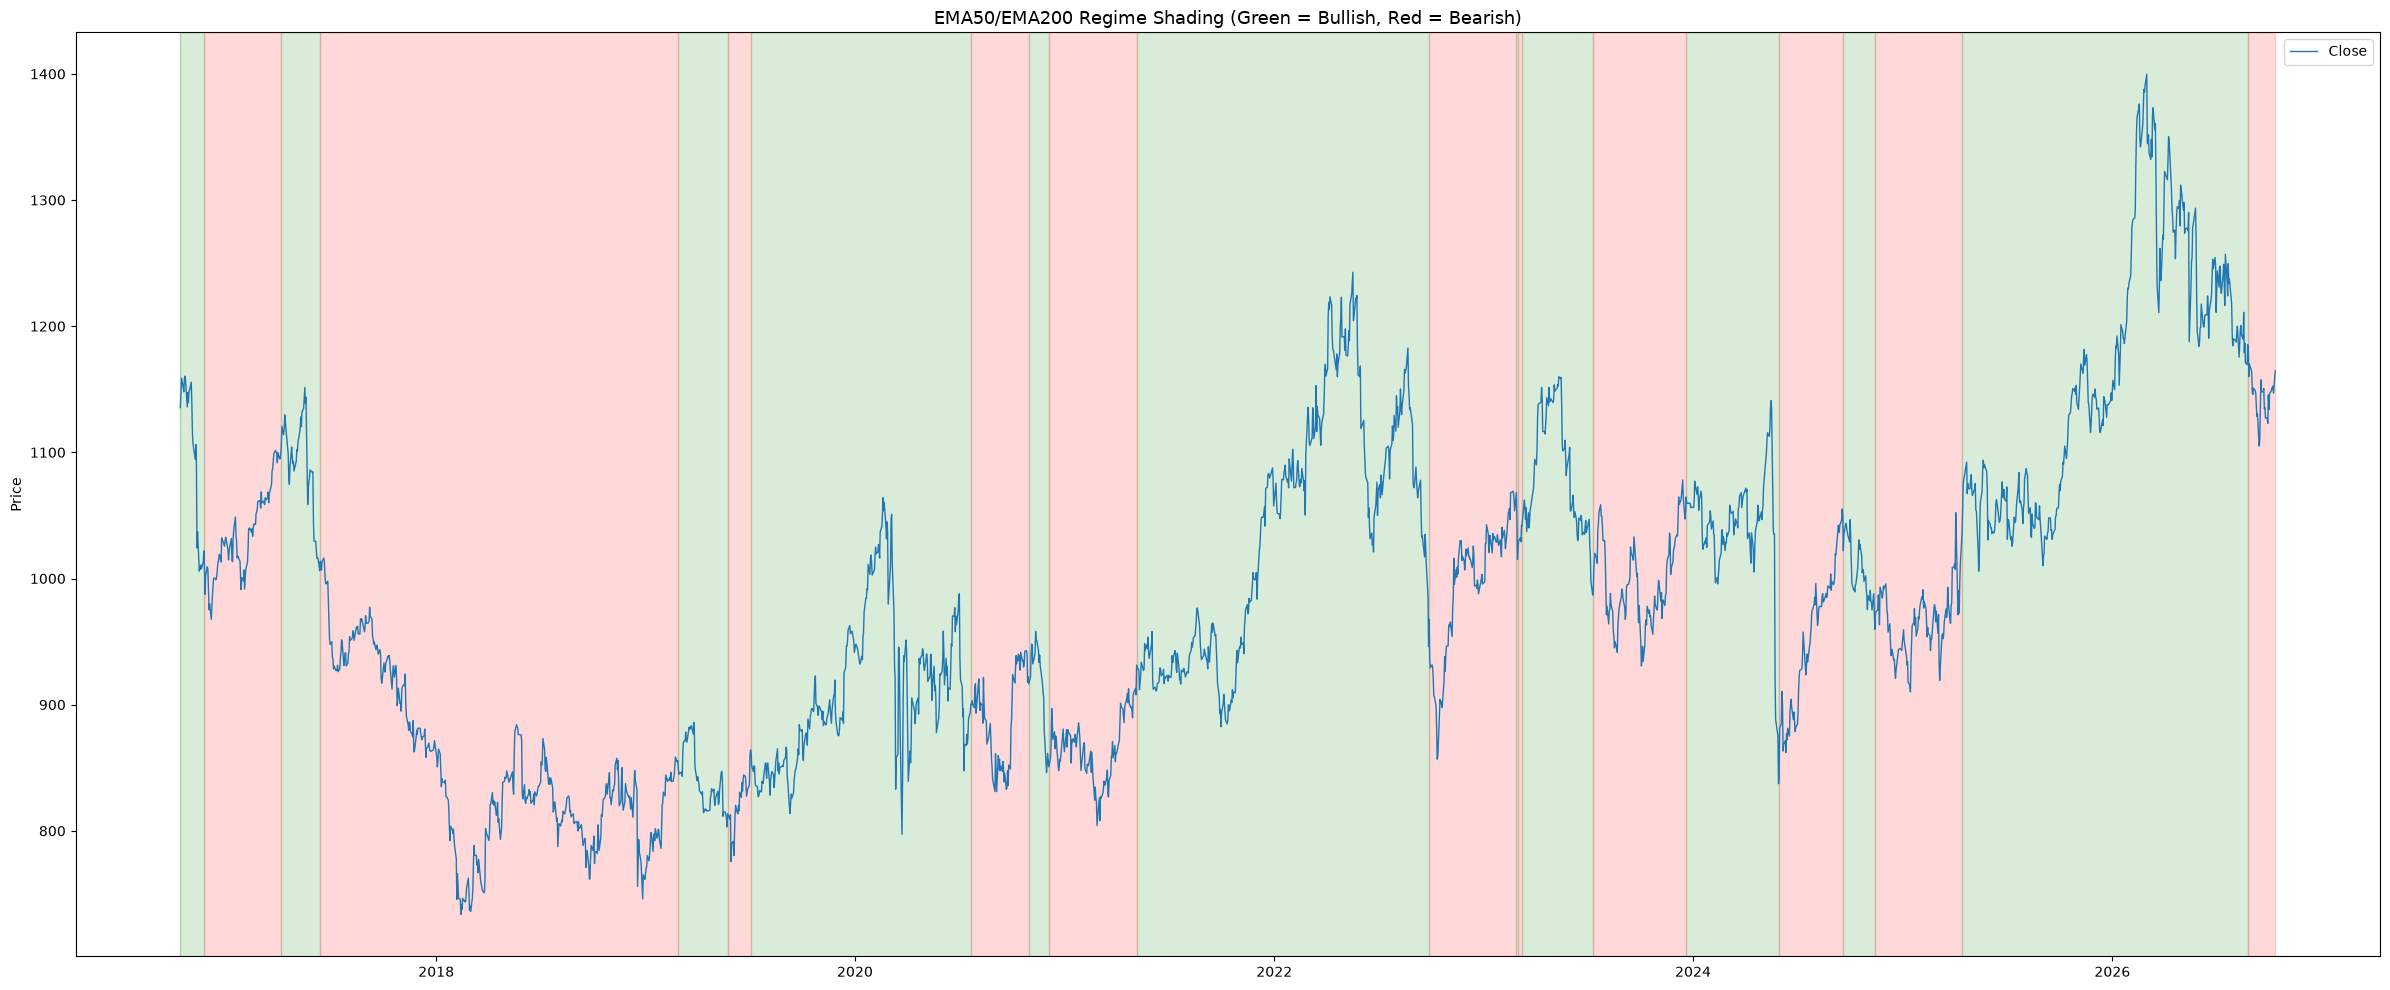

In [16]:
# === 15. Duration of EMA50/EMA200 Regimes & Returns ===
# How long does the market stay in golden cross or death cross regime?
# And what are the cumulative returns during those regimes?
cutoff = df.index.max() - pd.DateOffset(years=10)
dfd = df[df.index >= cutoff].copy()

bullish = dfd["ta_ema50"] > dfd["ta_ema200"]

# Find regime transitions
regime_change = bullish != bullish.shift(1)
regime_start_idx = regime_change[regime_change].index
if bullish.iloc[0]:
    regime_start_idx = [dfd.index[0]] + list(regime_start_idx)

regimes = []
for i in range(len(regime_start_idx)):
    start = regime_start_idx[i]
    end = regime_start_idx[i + 1] if i + 1 < len(regime_start_idx) else dfd.index[-1]
    regime_data = dfd.loc[start:end]
    reg_type = "GOLDEN CROSS" if bullish.iloc[dfd.index.get_loc(start)] else "DEATH CROSS"
    duration = len(regime_data)
    cum_ret = (regime_data["Close"].iloc[-1] / regime_data["Close"].iloc[0]) - 1
    avg_ret_5d = regime_data["ta_return_5d"].mean()
    avg_ret_10d = regime_data["ta_return_10d"].mean()
    avg_ret_20d = regime_data["ta_return_20d"].mean()
    win_rate_5d = (regime_data["ta_return_5d"] > 0).mean()
    max_dd = (regime_data["Close"] / regime_data["Close"].cummax() - 1).min()
    regimes.append({
        "Type": reg_type,
        "Start": start,
        "End": end,
        "Duration (days)": duration,
        "Cumulative Return": round(cum_ret, 5),
        "Avg 5d Ret": round(avg_ret_5d, 5),
        "Avg 10d Ret": round(avg_ret_10d, 5),
        "Avg 20d Ret": round(avg_ret_20d, 5),
        "Win Rate 5d": f"{win_rate_5d:.1%}",
        "Max Drawdown": f"{max_dd:.2%}",
    })

regime_df = pd.DataFrame(regimes)
print("Total regimes in last 10 years:", len(regime_df))
print("  Golden Cross (bullish) regimes:", (regime_df["Type"] == "GOLDEN CROSS").sum())
print("  Death Cross (bearish) regimes: ", (regime_df["Type"] == "DEATH CROSS").sum())
print()
print(regime_df.to_string(index=False))

# Summary comparison
gc_regs = regime_df[regime_df["Type"] == "GOLDEN CROSS"]
dc_regs = regime_df[regime_df["Type"] == "DEATH CROSS"]

print()
print("=== REGIME COMPARISON ===")
headers = ["Metric", "Golden Cross", "Death Cross"]
print(f"{headers[0]:<25} {headers[1]:>15} {headers[2]:>15}")
print("-" * 58)
print(f"{'Avg Duration (days)':<25} {gc_regs['Duration (days)'].mean():>15.1f} {dc_regs['Duration (days)'].mean():>15.1f}")
print(f"{'Avg Cumulative Return':<25} {gc_regs['Cumulative Return'].mean():>15.5f} {dc_regs['Cumulative Return'].mean():>15.5f}")
print(f"{'Avg Avg 5d Return':<25} {gc_regs['Avg 5d Ret'].mean():>15.5f} {dc_regs['Avg 5d Ret'].mean():>15.5f}")
gc_wr = gc_regs['Win Rate 5d'].str.rstrip('%').astype(float).mean() / 100
dc_wr = dc_regs['Win Rate 5d'].str.rstrip('%').astype(float).mean() / 100
print(f"{'Avg Win Rate 5d':<25} {gc_wr:>15.1%} {dc_wr:>15.1%}")
gc_dd = gc_regs['Max Drawdown'].str.rstrip('%').astype(float).mean()
dc_dd = dc_regs['Max Drawdown'].str.rstrip('%').astype(float).mean()
print(f"{'Avg Max Drawdown':<25} {gc_dd:>14.2f}% {dc_dd:>14.2f}%")

# --- Visualize: regime shading ---
fig, ax = plt.subplots(figsize=(24, 10))
ax.plot(dfd.index, dfd["Close"], label="Close", linewidth=1)

for _, row in regime_df.iterrows():
    if row["Type"] == "GOLDEN CROSS":
        ax.axvspan(row["Start"], row["End"], alpha=0.15, color="green")
    else:
        ax.axvspan(row["Start"], row["End"], alpha=0.15, color="red")

ax.set_title("EMA50/EMA200 Regime Shading (Green = Bullish, Red = Bearish)", fontsize=13)
ax.set_ylabel("Price")
ax.legend()
plt.tight_layout()
plt.show()

Total crossover signals in last 10 years: 21
  Golden Crosses: 10
  Death Crosses:  11

=== Spacing Between Consecutive Signals ===
  Min gap: 3 days
  Max gap: 623 days
  Avg gap: 178 days

=== Year-by-Year Summary ===
      golden_crosses  death_crosses  avg_return_5d  avg_return_20d  win_rate_5d
year                                                                           
2016               0              1      -0.009843       -0.036446     0.392857
2017               1              1      -0.003278       -0.014951     0.472222
2018               0              0      -0.001606       -0.002775     0.418972
2019               2              1       0.004103        0.016714     0.569170
2020               1              2      -0.000530       -0.005806     0.515748
2021               1              0       0.003954        0.017382     0.600791
2022               0              1      -0.000148       -0.000469     0.528000
2023               3              2       0.001095        0.

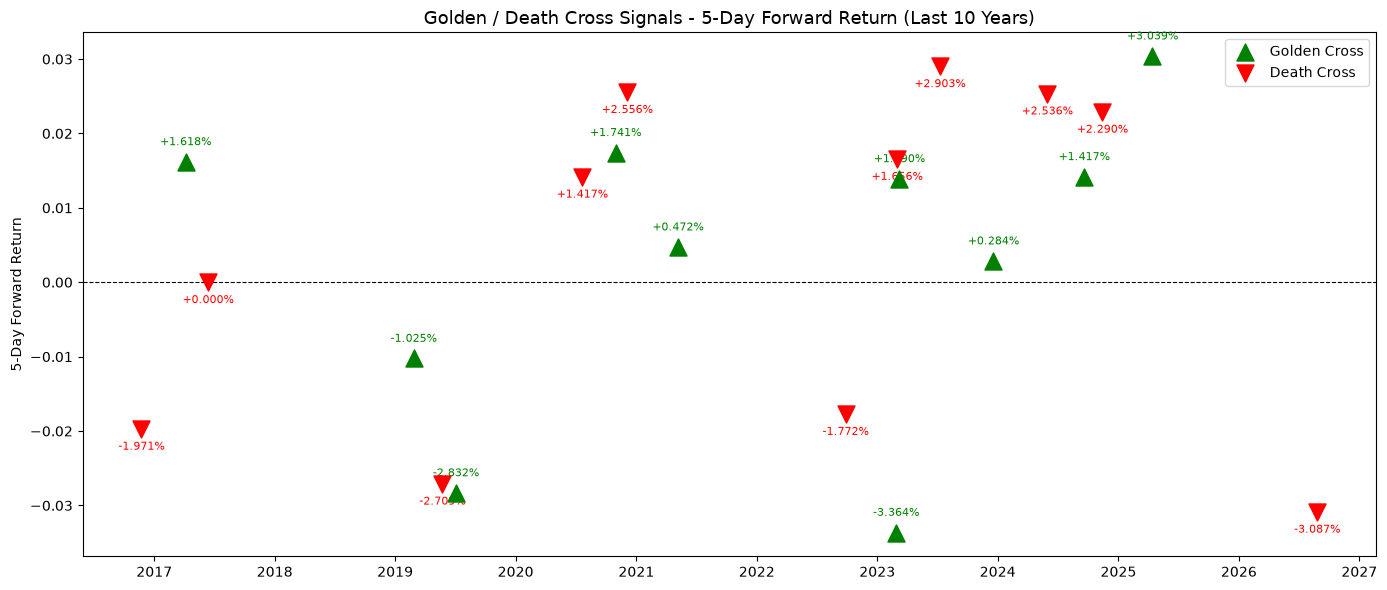

In [17]:
# === 16. Signal Reliability Over Time ===
# Year-by-year breakdown and spacing analysis
cutoff = df.index.max() - pd.DateOffset(years=10)
dfg = df[df.index >= cutoff].copy()

gc_days = dfg[dfg["golden_cross_strong"]].index
dc_days = dfg[dfg["death_cross_strong"]].index

all_gc = [(d, "GC") for d in gc_days]
all_dc = [(d, "DC") for d in dc_days]
all_signals = sorted(all_gc + all_dc, key=lambda x: x[0])

print("Total crossover signals in last 10 years:", len(all_signals))
print("  Golden Crosses:", len(gc_days))
print("  Death Crosses: ", len(dc_days))
print()

# Check spacing between signals
signal_dates = [s[0] for s in all_signals]
if len(signal_dates) > 1:
    gaps = [(signal_dates[i+1] - signal_dates[i]).days for i in range(len(signal_dates)-1)]
    print("=== Spacing Between Consecutive Signals ===")
    print("  Min gap:", min(gaps), "days")
    print("  Max gap:", max(gaps), "days")
    print("  Avg gap:", round(sum(gaps)/len(gaps)), "days")
    print()

# Year-by-year breakdown
dfg["year"] = dfg.index.year
yearly = dfg.groupby("year").agg(
    golden_crosses=("golden_cross_strong", "sum"),
    death_crosses=("death_cross_strong", "sum"),
    avg_return_5d=("ta_return_5d", "mean"),
    avg_return_20d=("ta_return_20d", "mean"),
    win_rate_5d=("ta_return_5d", lambda x: (x > 0).mean()),
)
print("=== Year-by-Year Summary ===")
print(yearly.to_string())

# Signal -> next 5d return scatter with annotations
gc_returns_5d = [(d, dfg.loc[d, "ta_return_5d"]) for d in gc_days if pd.notna(dfg.loc[d, "ta_return_5d"])]
dc_returns_5d = [(d, dfg.loc[d, "ta_return_5d"]) for d in dc_days if pd.notna(dfg.loc[d, "ta_return_5d"])]

fig, ax = plt.subplots(figsize=(14, 6))

if gc_returns_5d:
    gc_d, gc_r = zip(*gc_returns_5d)
    ax.scatter(gc_d, gc_r, color="green", s=150, marker="^", zorder=5, label="Golden Cross")
    for d, r in zip(gc_d, gc_r):
        ax.annotate(f"{r:+.3%}", (d, r), textcoords="offset points", xytext=(0, 12),
                    ha="center", fontsize=8, color="green")

if dc_returns_5d:
    dc_d, dc_r = zip(*dc_returns_5d)
    ax.scatter(dc_d, dc_r, color="red", s=150, marker="v", zorder=5, label="Death Cross")
    for d, r in zip(dc_d, dc_r):
        ax.annotate(f"{r:+.3%}", (d, r), textcoords="offset points", xytext=(0, -15),
                    ha="center", fontsize=8, color="red")

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_ylabel("5-Day Forward Return")
ax.set_title("Golden / Death Cross Signals - 5-Day Forward Return (Last 10 Years)", fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

=== GOLDEN CROSS - Trend Score Context ===
  Avg trend score at golden cross: 4.0
  Avg 5d forward return: 0.00274
  Avg 20d forward return: 0.00459

=== DEATH CROSS - Trend Score Context ===
  Avg trend score at death cross: -4.09
  Avg 5d forward return: 0.00347
  Avg 20d forward return: -0.0036

=== COMBINED SIGNAL ANALYSIS ===
Signal                              Count   Avg 5d Ret  Avg 10d Ret  Win Rate 5d
--------------------------------------------------------------------------------
GC + Bullish (score >= 0)              10      0.00274      0.00995        70.0%
DC + Bearish (score < 0)               11      0.00347      0.00356        54.5%


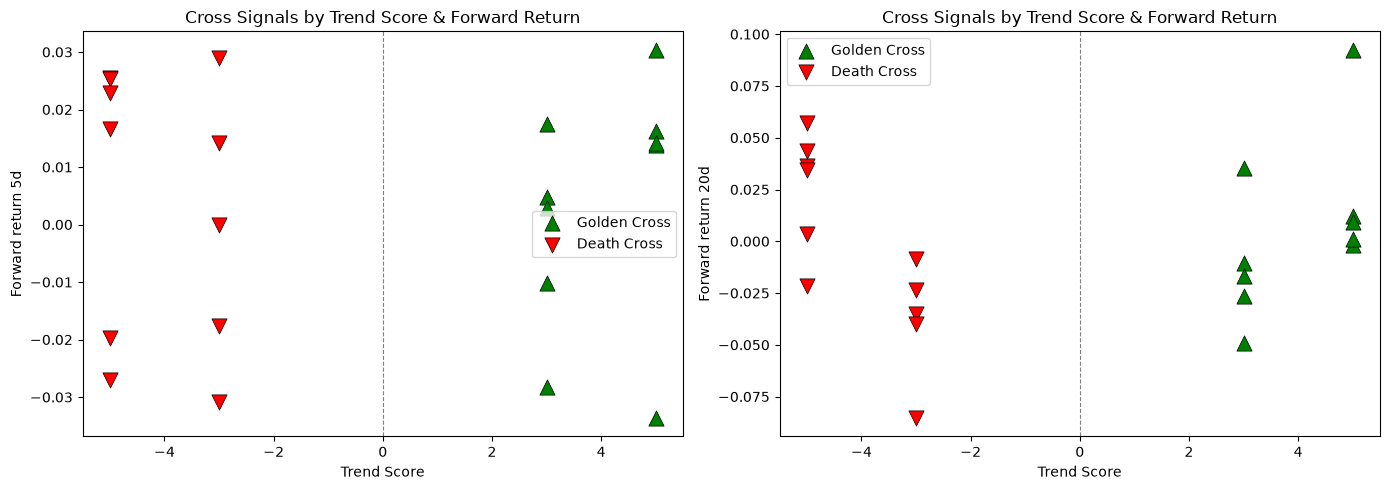

In [18]:
# === 17. Golden/Death Cross + Trend Score Combined Signal ===
# Does a Golden Cross that coincides with a high trend score
# produce stronger forward returns than a Golden Cross alone?
cutoff = df.index.max() - pd.DateOffset(years=10)
dfm = df[df.index >= cutoff].copy()

st_dir = dfm["ta_supertrend_direction"].fillna(-1)
dfm["score_ema20"] = (dfm["Close"] > dfm["ta_ema20"]).astype(int) * 2 - 1
dfm["score_ema50"] = (dfm["Close"] > dfm["ta_ema50"]).astype(int) * 2 - 1
dfm["score_ema200"] = (dfm["Close"] > dfm["ta_ema200"]).astype(int) * 2 - 1
dfm["score_cross"] = (dfm["ta_ema50"] > dfm["ta_ema200"]).astype(int) * 2 - 1
dfm["score_st"] = st_dir
dfm["trend_score"] = dfm["score_ema20"] + dfm["score_ema50"] + dfm["score_ema200"] + dfm["score_cross"] + dfm["score_st"]

gc = dfm[dfm["golden_cross_strong"]].copy()
dc = dfm[dfm["death_cross_strong"]].copy()

print("=== GOLDEN CROSS - Trend Score Context ===")
print("  Avg trend score at golden cross:", round(gc["trend_score"].mean(), 2))
print("  Avg 5d forward return:", round(gc["ta_return_5d"].mean(), 5))
print("  Avg 20d forward return:", round(gc["ta_return_20d"].mean(), 5))
print()

print("=== DEATH CROSS - Trend Score Context ===")
print("  Avg trend score at death cross:", round(dc["trend_score"].mean(), 2))
print("  Avg 5d forward return:", round(dc["ta_return_5d"].mean(), 5))
print("  Avg 20d forward return:", round(dc["ta_return_20d"].mean(), 5))
print()

# Split by bullish/bearish context
gc_bullish = gc[gc["trend_score"] >= 0]
gc_bearish = gc[gc["trend_score"] < 0]
dc_bullish = dc[dc["trend_score"] >= 0]
dc_bearish = dc[dc["trend_score"] < 0]

print("=== COMBINED SIGNAL ANALYSIS ===")
print(f"{'Signal':<35} {'Count':>5} {'Avg 5d Ret':>12} {'Avg 10d Ret':>12} {'Win Rate 5d':>12}")
print("-" * 80)
if len(gc_bullish):
    print(f"{'GC + Bullish (score >= 0)':<35} {len(gc_bullish):>5} {gc_bullish['ta_return_5d'].mean():>12.5f} {gc_bullish['ta_return_10d'].mean():>12.5f} {(gc_bullish['ta_return_5d'] > 0).mean():>12.1%}")
if len(gc_bearish):
    print(f"{'GC + Bearish (score < 0)':<35} {len(gc_bearish):>5} {gc_bearish['ta_return_5d'].mean():>12.5f} {gc_bearish['ta_return_10d'].mean():>12.5f} {(gc_bearish['ta_return_5d'] > 0).mean():>12.1%}")
if len(dc_bullish):
    print(f"{'DC + Bullish (score >= 0)':<35} {len(dc_bullish):>5} {dc_bullish['ta_return_5d'].mean():>12.5f} {dc_bullish['ta_return_10d'].mean():>12.5f} {(dc_bullish['ta_return_5d'] > 0).mean():>12.1%}")
if len(dc_bearish):
    print(f"{'DC + Bearish (score < 0)':<35} {len(dc_bearish):>5} {dc_bearish['ta_return_5d'].mean():>12.5f} {dc_bearish['ta_return_10d'].mean():>12.5f} {(dc_bearish['ta_return_5d'] > 0).mean():>12.1%}")

# --- Visualize: scatter of score vs forward return ---
all_crosses = pd.DataFrame()
gc_temp = gc.copy()
gc_temp["signal"] = "Golden Cross"
gc_temp["score"] = dfm.loc[gc.index, "trend_score"]
dc_temp = dc.copy()
dc_temp["signal"] = "Death Cross"
dc_temp["score"] = dfm.loc[dc.index, "trend_score"]
all_crosses = pd.concat([gc_temp, dc_temp])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ret_key in zip(axes, ["ta_return_5d", "ta_return_20d"]):
    gc_sub = all_crosses[all_crosses["signal"] == "Golden Cross"]
    dc_sub = all_crosses[all_crosses["signal"] == "Death Cross"]
    if len(gc_sub):
        ax.scatter(gc_sub["score"], gc_sub[ret_key], color="green", s=120, marker="^",
                  edgecolors="black", linewidth=0.5, label="Golden Cross")
    if len(dc_sub):
        ax.scatter(dc_sub["score"], dc_sub[ret_key], color="red", s=120, marker="v",
                  edgecolors="black", linewidth=0.5, label="Death Cross")
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_ylabel(ret_key.replace("ta_", "Forward ").replace("_", " "))
    ax.set_xlabel("Trend Score")
    ax.set_title("Cross Signals by Trend Score & Forward Return")
    ax.legend()

plt.tight_layout()
plt.show()

=== EMA20 > EMA50 Signal Analysis (Last 10 Years) ===
Time period: 2016-10-12 to 2026-10-12
Total bars: 2526

Bullish (EMA20 > EMA50): 1342 (53.1%)
Bearish (EMA20 <= EMA50): 1184 (46.9%)

=== Average Forward Returns by Signal ===
ta_return_5d: Bullish=-0.061% vs Bearish=0.164% (diff=-0.0022)
ta_return_10d: Bullish=-0.124% vs Bearish=0.313% (diff=-0.0044)
ta_return_20d: Bullish=-0.296% vs Bearish=0.689% (diff=-0.0098)

=== Point-Biserial Correlation ===
Signal vs ta_return_5d: r = -0.0384
Signal vs ta_return_10d: r = -0.0549
Signal vs ta_return_20d: r = -0.0883

=== Return Direction Accuracy ===
ta_return_5d: Accuracy=49.7% (Correct=1252, Total=2521)
  Bullish: 701 correct, 641 wrong
  Bearish: 551 correct, 628 wrong
ta_return_10d: Accuracy=49.6% (Correct=1249, Total=2516)
  Bullish: 743 correct, 599 wrong
  Bearish: 506 correct, 668 wrong
ta_return_20d: Accuracy=48.1% (Correct=1206, Total=2506)
  Bullish: 683 correct, 659 wrong
  Bearish: 523 correct, 641 wrong


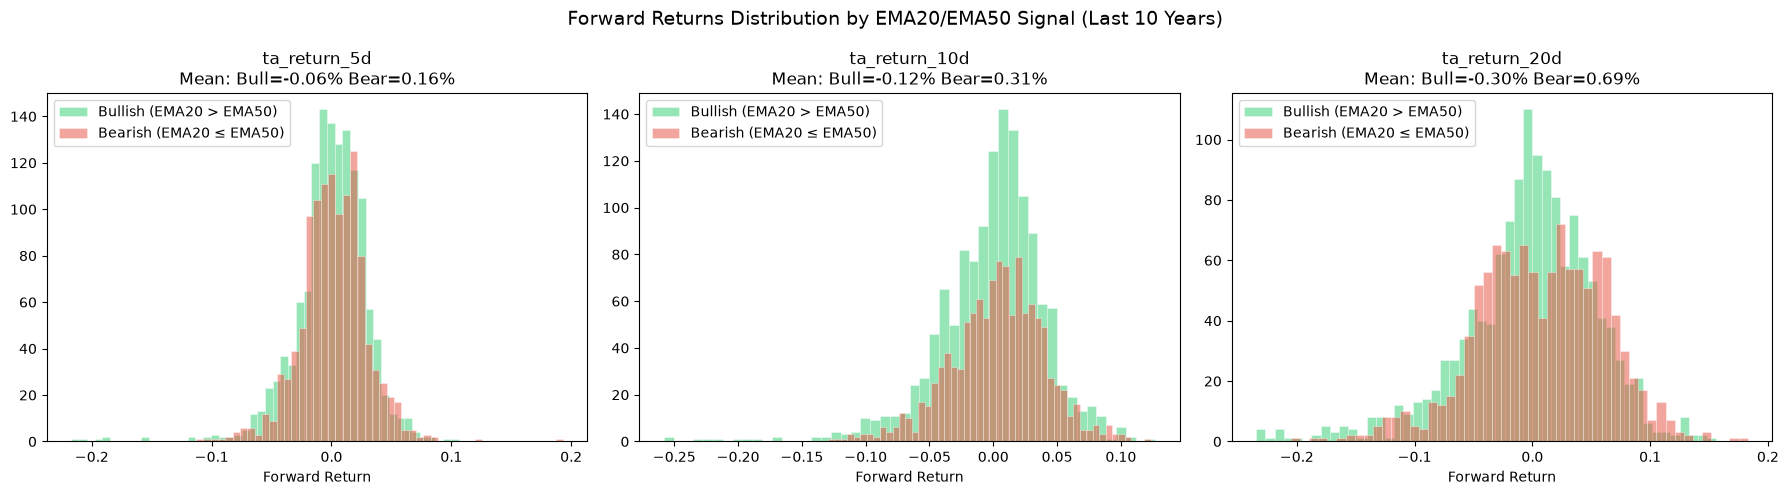

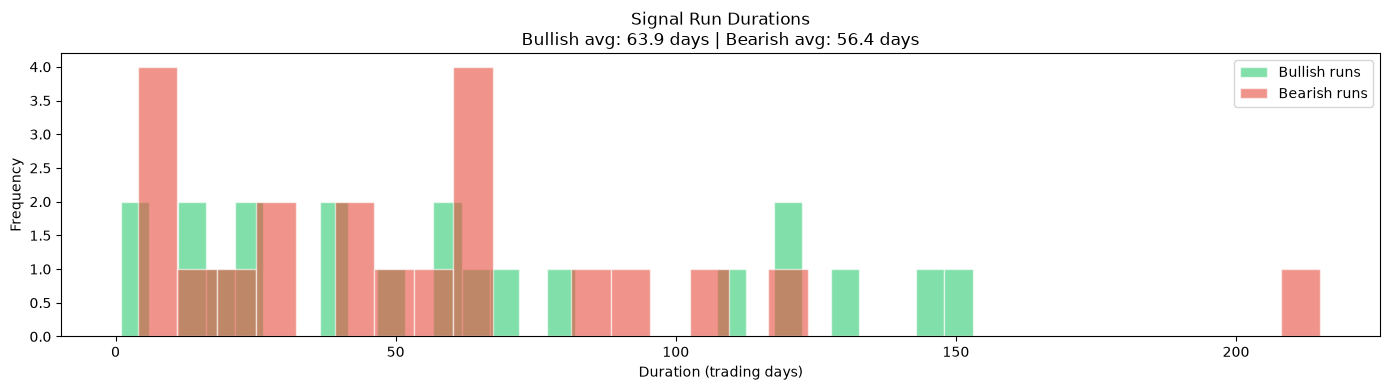

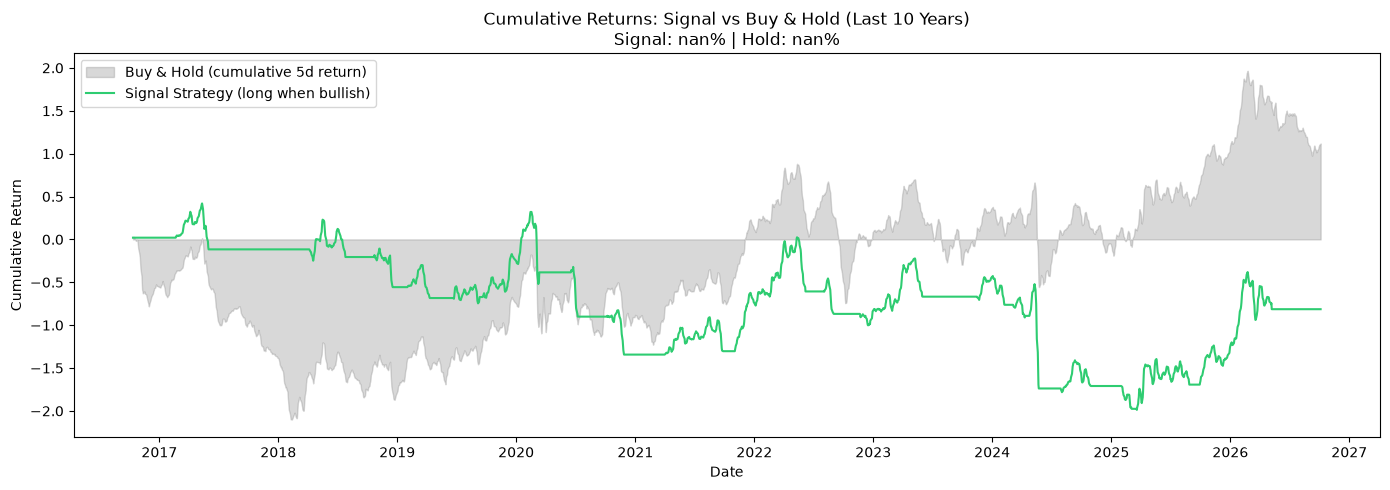

In [19]:
# === 14. Returns vs EMA20 > EMA50 Signal (Last 10 Years) ===
cutoff14 = df.index.max() - pd.DateOffset(years=10)
df14 = df[df.index >= cutoff14].copy()

# Create boolean signal: EMA20 above EMA50 = bullish
df14["ema20_above_ema50"] = df14["ta_ema20"] > df14["ta_ema50"]

# Summary statistics
print("=== EMA20 > EMA50 Signal Analysis (Last 10 Years) ===")
print(f"Time period: {df14.index.min().date()} to {df14.index.max().date()}")
print(f"Total bars: {len(df14)}")
print(f"\nBullish (EMA20 > EMA50): {df14['ema20_above_ema50'].sum()} ({df14['ema20_above_ema50'].mean()*100:.1f}%)")
print(f"Bearish (EMA20 <= EMA50): {(~df14['ema20_above_ema50']).sum()} ({(1-df14['ema20_above_ema50'].mean())*100:.1f}%)")

# Average forward returns by signal
print("\n=== Average Forward Returns by Signal ===")
returns_cols = ["ta_return_5d", "ta_return_10d", "ta_return_20d"]
for ret_col in returns_cols:
    bull_mean = df14[df14["ema20_above_ema50"]][ret_col].mean()
    bear_mean = df14[~df14["ema20_above_ema50"]][ret_col].mean()
    print(f"{ret_col}: Bullish={bull_mean*100:.3f}% vs Bearish={bear_mean*100:.3f}% (diff={bull_mean-bear_mean:.4f})")

# Correlation between signal and returns
print("\n=== Point-Biserial Correlation ===")
for ret_col in returns_cols:
    corr = df14["ema20_above_ema50"].corr(df14[ret_col])
    print(f"Signal vs {ret_col}: r = {corr:.4f}")

# Contingency analysis: signal direction vs actual return direction
print("\n=== Return Direction Accuracy ===")
for ret_col in returns_cols:
    # Bullish signal, positive return = correct
    bullish_correct = df14[(df14["ema20_above_ema50"]) & (df14[ret_col] > 0)].shape[0]
    # Bullish signal, negative return = wrong
    bullish_wrong = df14[(df14["ema20_above_ema50"]) & (df14[ret_col] <= 0)].shape[0]
    # Bearish signal, negative return = correct
    bearish_correct = df14[(~df14["ema20_above_ema50"]) & (df14[ret_col] < 0)].shape[0]
    # Bearish signal, positive return = wrong
    bearish_wrong = df14[(~df14["ema20_above_ema50"]) & (df14[ret_col] >= 0)].shape[0]
    total_correct = bullish_correct + bearish_correct
    total = bullish_correct + bullish_wrong + bearish_correct + bearish_wrong
    accuracy = total_correct / total if total else 0
    print(f"{ret_col}: Accuracy={accuracy*100:.1f}% (Correct={total_correct}, Total={total})")
    print(f"  Bullish: {bullish_correct} correct, {bullish_wrong} wrong")
    print(f"  Bearish: {bearish_correct} correct, {bearish_wrong} wrong")

# Visualization: Returns distribution by signal
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {True: "#2ecc71", False: "#e74c3c"}
labels = {True: "Bullish (EMA20 > EMA50)", False: "Bearish (EMA20 ≤ EMA50)"}

for idx, ret_col in enumerate(returns_cols):
    ax = axes[idx]
    for signal_val in [True, False]:
        subset = df14[df14["ema20_above_ema50"] == signal_val][ret_col].dropna()
        ax.hist(subset, bins=50, alpha=0.5, color=colors[signal_val],
                label=labels[signal_val], edgecolor="white", linewidth=0.5)
    ax.set_title(f"{ret_col}\nMean: Bull={df14[df14['ema20_above_ema50']][ret_col].mean()*100:.2f}% "
                 f"Bear={df14[~df14['ema20_above_ema50']][ret_col].mean()*100:.2f}%")
    ax.set_xlabel("Forward Return")
    ax.legend()

plt.suptitle("Forward Returns Distribution by EMA20/EMA50 Signal (Last 10 Years)", fontsize=14)
plt.tight_layout()
plt.show()

# Visualization: Signal persistence over time
fig2, ax2 = plt.subplots(figsize=(14, 4))
bull_duration = []
bear_duration = []
current_signal = df14.iloc[0]["ema20_above_ema50"]
count = 1
for i in range(1, len(df14)):
    if df14.iloc[i]["ema20_above_ema50"] == current_signal:
        count += 1
    else:
        if current_signal:
            bull_duration.append(count)
        else:
            bear_duration.append(count)
        current_signal = df14.iloc[i]["ema20_above_ema50"]
        count = 1
# Add last run
if current_signal:
    bull_duration.append(count)
else:
    bear_duration.append(count)

ax2.hist(bull_duration, bins=30, alpha=0.6, color="#2ecc71", label="Bullish runs", edgecolor="white")
ax2.hist(bear_duration, bins=30, alpha=0.6, color="#e74c3c", label="Bearish runs", edgecolor="white")
ax2.set_xlabel("Duration (trading days)")
ax2.set_ylabel("Frequency")
ax2.set_title(f"Signal Run Durations\nBullish avg: {np.mean(bull_duration):.1f} days | Bearish avg: {np.mean(bear_duration):.1f} days")
ax2.legend()
plt.tight_layout()
plt.show()

# Visualization: Signal vs cumulative return
fig3, ax3 = plt.subplots(figsize=(14, 5))
df14_sorted = df14.sort_index()
ax3.fill_between(df14_sorted.index, df14_sorted["ta_return_5d"].cumsum(),
                 alpha=0.3, color="gray", label="Buy & Hold (cumulative 5d return)")
df14_sorted["signal_return"] = df14_sorted["ema20_above_ema50"].astype(int) * df14_sorted["ta_return_5d"]
ax3.plot(df14_sorted.index, df14_sorted["signal_return"].cumsum(),
         color="#2ecc71", linewidth=1.5, label="Signal Strategy (long when bullish)")
final_hold = df14_sorted["ta_return_5d"].cumsum().iloc[-1]
final_signal = df14_sorted["signal_return"].cumsum().iloc[-1]
ax3.set_title(f"Cumulative Returns: Signal vs Buy & Hold (Last 10 Years)\nSignal: {final_signal*100:.1f}% | Hold: {final_hold*100:.1f}%")
ax3.set_xlabel("Date")
ax3.set_ylabel("Cumulative Return")
ax3.legend()
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()